# Deep Learning Assignment 1

## Task 1

In [2]:
# importing all used packages and setting seeds for reproducibility
import numpy as np
import pandas as pd
import tensorflow as tf
import random
from tensorflow import keras
from tensorflow.keras import regularizers
from tensorflow.keras.datasets import fashion_mnist, cifar10
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Flatten, Conv2D, MaxPooling2D, Input, BatchNormalization
from tensorflow.keras.optimizers import RMSprop, Adam, SGD
from tensorflow.keras.callbacks import EarlyStopping

# setting seeds for reproducibility
seed = 21
np.random.seed(seed)
tf.random.set_seed(seed)
random.seed(seed)

# defining data loading function for fashion_mnist
def load_and_preprocess_fashion_mnist():
    num_classes = 10
    # the data, shuffled and split between train and test sets
    (x_train_complete, y_train_complete), (x_test, y_test) = fashion_mnist.load_data()

    # shuffling data using random seed for reproducibility
    indices = np.arange(len(x_train_complete))
    np.random.shuffle(indices)
    x_train_complete = x_train_complete[indices]
    y_train_complete = y_train_complete[indices]

    # splitting train_complete into validation and training sets
    x_valid = x_train_complete[:6000]
    y_valid = y_train_complete[:6000]
    x_train = x_train_complete[6000:]
    y_train = y_train_complete[6000:]

    # reshape all three sets
    x_train = x_train.reshape(54000, 784)
    x_valid = x_valid.reshape(6000, 784)
    x_test = x_test.reshape(10000, 784)

    # normalizing pixel values to [0, 1]
    x_train = x_train.astype("float32") / 255
    x_valid = x_valid.astype("float32") / 255
    x_test = x_test.astype("float32") / 255

    # convert class vectors to binary class matrices
    y_train = keras.utils.to_categorical(y_train, num_classes)
    y_valid = keras.utils.to_categorical(y_valid, num_classes)
    y_test = keras.utils.to_categorical(y_test, num_classes)

    # defining input shape for MLP (flattened)
    input_shape = (784,)

    print("x_train shape:", x_train.shape)
    print(f"{x_train.shape[0]} train samples")
    print(f"{x_valid.shape[0]} validation samples")
    print(f"{x_test.shape[0]} test samples")

    return (x_train, y_train), (x_valid, y_valid), (x_test, y_test), input_shape

### Initial Exploration (manually)

In this section, we conduct initial experiments to understand the baseline performance and the effects of different hyperparameters.

In [3]:
'''experiment 1 (baseline)

training a simple deep nn on the fashion mnist dataset

'''

batch_size = 128
num_classes = 10
epochs = 20

(x_train, y_train), (x_valid, y_valid), (x_test, y_test), input_shape = load_and_preprocess_fashion_mnist()

# defining the model architecture (2 hidden layers with 512 neurons each)
model = Sequential()
model.add(Dense(512, activation = "relu", input_shape = input_shape))
model.add(Dropout(0.2))
model.add(Dense(512, activation = "relu"))
model.add(Dropout(0.2))
model.add(Dense(num_classes, activation = "softmax"))

model.summary()

# compiling the model
model.compile(loss = "categorical_crossentropy",
              optimizer = RMSprop(learning_rate = 0.001),
              metrics = ["accuracy"])

early_stop = EarlyStopping(monitor = "val_loss", patience = 3, restore_best_weights = True, verbose = 1)

history = model.fit(x_train, y_train,
                    batch_size = batch_size,
                    epochs = epochs,
                    verbose = 1,
                    validation_data = (x_valid, y_valid),
                    callbacks = [early_stop])

# evaluating on test set
score = model.evaluate(x_test, y_test, verbose = 0)
print("Test loss:", score[0])
print("Test accuracy:", score[1])

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
x_train shape: (54000, 784)
54000 train samples
6000 validation samples
10000 test samples


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 512)            │       401,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 512)            │       262,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         5,130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 669,706 (2.55 MB)

 Trainable params: 669,706 (2.55 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 17s 31ms/step - accuracy: 0.7208 - loss: 0.7775 - val_accuracy: 0.8225 - val_loss: 0.4777
Epoch 2/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8463 - loss: 0.4169 - val_accuracy: 0.8652 - val_loss: 0.3590
Epoch 3/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8624 - loss: 0.3700 - val_accuracy: 0.8735 - val_loss: 0.3404
Epoch 4/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8749 - loss: 0.3392 - val_accuracy: 0.8763 - val_loss: 0.3253
Epoch 5/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8807 - loss: 0.3234 - val_accuracy: 0.8830 - val_loss: 0.3112
Epoch 6/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8835 - loss: 0.3108 - val_accuracy: 0.8838 - val_loss: 0.3062
Epoch 7/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8886 - loss: 0.2993 - val_accuracy: 0.8860 - val_loss: 0.3112
Epoch 8/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8928 - loss: 0.2906 - val_accuracy: 

Changes to the initial deep NN on the Fashion-MNIST dataset:

- Importing fashion_mnist instead of mnist
- Importing training data as train_complete and then splitting it into validation and training sets (6000 for validation, 54000 for training)
- Adding validation set to all preprocessing steps (reshape, normalize, etc.)
- Using validation_data parameter in model.fit() to monitor performance on the validation set during training, keeping the test set untouched for final evaluation


Observations from baseline experiment:

- earlystopping seems to be working as intended since a val_accuracy of 89% is reached after 12 epochs already
- reaching a test accuracy of 88%

Next:

- try different optimizer adam

- playing around with the dropout rate

For the report we should document all these experiments maybe in the form of a table where we document the changes and the effect on accuracy and anything noteworthy (implemented later in this notebook)

Something like:

- Experiment | Optimizer | Dropout Rate | Test Accuracy | Notes
- 1 (baseline) | RMSprop | 0.2 | 88% | signs of overfitting after epoch 9
- 2 (diff opt) | Adam | 0.2 | tbd | tbd
- 3 (diff dr) | RMSprop | 0.4 | tbd | tbd
- 4 (diff opt + dr) | Adam | 0.4 | tbd | tbd


In [4]:
'''experiment 2 (adam + 0.2)

using Adam optimizer

'''

batch_size = 128
num_classes = 10
epochs = 20

(x_train, y_train), (x_valid, y_valid), (x_test, y_test), input_shape = load_and_preprocess_fashion_mnist()

# defining the model architecture
model = Sequential()
model.add(Dense(512, activation = "relu", input_shape = input_shape))
model.add(Dropout(0.2))
model.add(Dense(512, activation = "relu"))
model.add(Dropout(0.2))
model.add(Dense(num_classes, activation = "softmax"))

model.summary()

# compiling with Adam optimizer
model.compile(loss = "categorical_crossentropy",
              optimizer = Adam(learning_rate = 0.001),
              metrics = ["accuracy"])

# early stopping: stops training when validation loss doesn't improve for 3 consecutive epochs
early_stop = EarlyStopping(monitor = "val_loss", patience = 3, restore_best_weights = True, verbose = 1)

history = model.fit(x_train, y_train,
                    batch_size = batch_size,
                    epochs = epochs,
                    verbose = 1,
                    validation_data = (x_valid, y_valid),
                    callbacks = [early_stop])

# evaluating on test set
score = model.evaluate(x_test, y_test, verbose = 0)
print("Test loss:", score[0])
print("Test accuracy:", score[1])

x_train shape: (54000, 784)
54000 train samples
6000 validation samples
10000 test samples


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 512)            │       401,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 512)            │       262,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │         5,130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 669,706 (2.55 MB)

 Trainable params: 669,706 (2.55 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 7s 10ms/step - accuracy: 0.7600 - loss: 0.6841 - val_accuracy: 0.8622 - val_loss: 0.3771
Epoch 2/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8543 - loss: 0.3964 - val_accuracy: 0.8660 - val_loss: 0.3535
Epoch 3/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8677 - loss: 0.3575 - val_accuracy: 0.8772 - val_loss: 0.3299
Epoch 4/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8757 - loss: 0.3376 - val_accuracy: 0.8795 - val_loss: 0.3172
Epoch 5/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8817 - loss: 0.3185 - val_accuracy: 0.8850 - val_loss: 0.3149
Epoch 6/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8876 - loss: 0.3010 - val_accuracy: 0.8813 - val_loss: 0.3159
Epoch 7/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8911 - loss: 0.2899 - val_accuracy: 0.8862 - val_loss: 0.3029
Epoch 8/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8946 - loss: 0.2801 - val_accuracy: 0

Notes on experiment 2:
- Adam optimizer with early stopping (patience=3) for consistent comparison
- similar amount of training epochs
- slightly better performance on test set (minimally)

Up next:
- Using RMSprop with a higher dropout rate of 0.4

In [5]:
'''experiment 3 (rmsprop + 0.4)

using RMSprop optimizer with higher dropout rate of 0.4

'''

batch_size = 128
num_classes = 10
epochs = 20

(x_train, y_train), (x_valid, y_valid), (x_test, y_test), input_shape = load_and_preprocess_fashion_mnist()

# defining the model architecture with higher dropout
model = Sequential()
model.add(Dense(512, activation = "relu", input_shape = input_shape))
model.add(Dropout(0.4))
model.add(Dense(512, activation = "relu"))
model.add(Dropout(0.4))
model.add(Dense(num_classes, activation = "softmax"))

model.summary()

# compiling with RMSprop optimizer
model.compile(loss = "categorical_crossentropy",
              optimizer = RMSprop(learning_rate = 0.001),
              metrics = ["accuracy"])

early_stop = EarlyStopping(monitor = "val_loss", patience = 3, restore_best_weights = True, verbose = 1)

history = model.fit(x_train, y_train,
                    batch_size = batch_size,
                    epochs = epochs,
                    verbose = 1,
                    validation_data = (x_valid, y_valid),
                    callbacks = [early_stop])

# evaluating on test set
score = model.evaluate(x_test, y_test, verbose = 0)
print("Test loss:", score[0])
print("Test accuracy:", score[1])

x_train shape: (54000, 784)
54000 train samples
6000 validation samples
10000 test samples


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_6 (Dense)                 │ (None, 512)            │       401,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 512)            │       262,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 10)             │         5,130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 669,706 (2.55 MB)

 Trainable params: 669,706 (2.55 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 6s 10ms/step - accuracy: 0.7114 - loss: 0.8064 - val_accuracy: 0.8523 - val_loss: 0.4060
Epoch 2/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8333 - loss: 0.4574 - val_accuracy: 0.8705 - val_loss: 0.3720
Epoch 3/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8503 - loss: 0.4126 - val_accuracy: 0.8758 - val_loss: 0.3484
Epoch 4/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8603 - loss: 0.3893 - val_accuracy: 0.8772 - val_loss: 0.3428
Epoch 5/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8657 - loss: 0.3717 - val_accuracy: 0.8725 - val_loss: 0.3416
Epoch 6/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8666 - loss: 0.3653 - val_accuracy: 0.8852 - val_loss: 0.3269
Epoch 7/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8730 - loss: 0.3555 - val_accuracy: 0.8828 - val_loss: 0.3230
Epoch 8/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8752 - loss: 0.3471 - val_accuracy: 0

Notes on experiment 3:
- We can see that the model learns slower with a higher dropout rate
- Increasing the dropout rate increased the model's performance slightly but still worse than Adam with 0.2 dr

Up next:
- Combining Adam with higher dropout rate of 0.4

In [6]:
'''experiment 4 (adam + 0.4)

using Adam optimizer with higher dropout rate of 0.4

'''

batch_size = 128
num_classes = 10
epochs = 20

(x_train, y_train), (x_valid, y_valid), (x_test, y_test), input_shape = load_and_preprocess_fashion_mnist()

# defining the model architecture with higher dropout
model = Sequential()
model.add(Dense(512, activation = "relu", input_shape = input_shape))
model.add(Dropout(0.4))
model.add(Dense(512, activation = "relu"))
model.add(Dropout(0.4))
model.add(Dense(num_classes, activation = "softmax"))

model.summary()

# compiling with Adam optimizer
model.compile(loss = "categorical_crossentropy",
              optimizer = Adam(learning_rate = 0.001),
              metrics = ["accuracy"])

early_stop = EarlyStopping(monitor = "val_loss", patience = 3, restore_best_weights = True, verbose = 1)

history = model.fit(x_train, y_train,
                    batch_size = batch_size,
                    epochs = epochs,
                    verbose = 1,
                    validation_data = (x_valid, y_valid),
                    callbacks = [early_stop])

# evaluating on test set
score = model.evaluate(x_test, y_test, verbose = 0)
print("Test loss:", score[0])
print("Test accuracy:", score[1])

x_train shape: (54000, 784)
54000 train samples
6000 validation samples
10000 test samples


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_9 (Dense)                 │ (None, 512)            │       401,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 512)            │       262,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 10)             │         5,130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 669,706 (2.55 MB)

 Trainable params: 669,706 (2.55 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 7s 11ms/step - accuracy: 0.7207 - loss: 0.7808 - val_accuracy: 0.8593 - val_loss: 0.3851
Epoch 2/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8392 - loss: 0.4464 - val_accuracy: 0.8675 - val_loss: 0.3564
Epoch 3/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8511 - loss: 0.4039 - val_accuracy: 0.8727 - val_loss: 0.3446
Epoch 4/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8596 - loss: 0.3844 - val_accuracy: 0.8802 - val_loss: 0.3268
Epoch 5/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8640 - loss: 0.3691 - val_accuracy: 0.8798 - val_loss: 0.3245
Epoch 6/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8679 - loss: 0.3547 - val_accuracy: 0.8845 - val_loss: 0.3196
Epoch 7/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8713 - loss: 0.3457 - val_accuracy: 0.8802 - val_loss: 0.3243
Epoch 8/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8760 - loss: 0.3335 - val_accuracy: 0

Notes on experiment 4:
- just as good as Adam with 0.2 but takes longer to learn

Next up:
- fewer neurons with RMSprop and dr 0.2

In [7]:
'''experiment 5 (smaller model: rmsprop + 0.2)

testing if a model with fewer neurons (256 instead of 512) affects performance
using RMSprop optimizer with dropout rate of 0.2

'''

batch_size = 128
num_classes = 10
epochs = 20

(x_train, y_train), (x_valid, y_valid), (x_test, y_test), input_shape = load_and_preprocess_fashion_mnist()

# defining the model architecture with fewer neurons per layer
model = Sequential()
model.add(Dense(256, activation = "relu", input_shape = input_shape))
model.add(Dropout(0.2))
model.add(Dense(256, activation = "relu"))
model.add(Dropout(0.2))
model.add(Dense(num_classes, activation = "softmax"))

model.summary()

# compiling with RMSprop optimizer
model.compile(loss = "categorical_crossentropy",
              optimizer = RMSprop(learning_rate = 0.001),
              metrics = ["accuracy"])

early_stop = EarlyStopping(monitor = "val_loss", patience = 3, restore_best_weights = True, verbose = 1)

history = model.fit(x_train, y_train,
                    batch_size = batch_size,
                    epochs = epochs,
                    verbose = 1,
                    validation_data = (x_valid, y_valid),
                    callbacks = [early_stop])

# evaluating on test set
score = model.evaluate(x_test, y_test, verbose = 0)
print("Test loss:", score[0])
print("Test accuracy:", score[1])

x_train shape: (54000, 784)
54000 train samples
6000 validation samples
10000 test samples


Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_12 (Dense)                │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 269,322 (1.03 MB)

 Trainable params: 269,322 (1.03 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 15s 26ms/step - accuracy: 0.7121 - loss: 0.7972 - val_accuracy: 0.8367 - val_loss: 0.4645
Epoch 2/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8409 - loss: 0.4316 - val_accuracy: 0.8677 - val_loss: 0.3714
Epoch 3/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8569 - loss: 0.3832 - val_accuracy: 0.8787 - val_loss: 0.3361
Epoch 4/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8686 - loss: 0.3554 - val_accuracy: 0.8887 - val_loss: 0.3235
Epoch 5/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8746 - loss: 0.3348 - val_accuracy: 0.8860 - val_loss: 0.3158
Epoch 6/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8803 - loss: 0.3218 - val_accuracy: 0.8895 - val_loss: 0.3149
Epoch 7/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8842 - loss: 0.3097 - val_accuracy: 0.8922 - val_loss: 0.3105
Epoch 8/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8859 - loss: 0.3012 - val_accuracy: 

In [8]:
'''experiment 6 (smaller model: adam + 0.2)

testing if a model with fewer neurons (256 instead of 512) affects performance
using Adam optimizer with dropout rate of 0.2

'''

batch_size = 128
num_classes = 10
epochs = 20

(x_train, y_train), (x_valid, y_valid), (x_test, y_test), input_shape = load_and_preprocess_fashion_mnist()

# defining the model architecture with fewer neurons per layer
model = Sequential()
model.add(Dense(256, activation = "relu", input_shape = input_shape))
model.add(Dropout(0.2))
model.add(Dense(256, activation = "relu"))
model.add(Dropout(0.2))
model.add(Dense(num_classes, activation = "softmax"))

model.summary()

# compiling with Adam optimizer
model.compile(loss = "categorical_crossentropy",
              optimizer = Adam(learning_rate = 0.001),
              metrics = ["accuracy"])

early_stop = EarlyStopping(monitor = "val_loss", patience = 3, restore_best_weights = True, verbose = 1)

history = model.fit(x_train, y_train,
                    batch_size = batch_size,
                    epochs = epochs,
                    verbose = 1,
                    validation_data = (x_valid, y_valid),
                    callbacks = [early_stop])

# evaluating on test set
score = model.evaluate(x_test, y_test, verbose = 0)
print("Test loss:", score[0])
print("Test accuracy:", score[1])

x_train shape: (54000, 784)
54000 train samples
6000 validation samples
10000 test samples


Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_15 (Dense)                │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_11 (Dropout)            │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 269,322 (1.03 MB)

 Trainable params: 269,322 (1.03 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 7s 10ms/step - accuracy: 0.7325 - loss: 0.7602 - val_accuracy: 0.8488 - val_loss: 0.4113
Epoch 2/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8491 - loss: 0.4164 - val_accuracy: 0.8677 - val_loss: 0.3745
Epoch 3/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8623 - loss: 0.3745 - val_accuracy: 0.8700 - val_loss: 0.3519
Epoch 4/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8734 - loss: 0.3447 - val_accuracy: 0.8713 - val_loss: 0.3524
Epoch 5/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8754 - loss: 0.3310 - val_accuracy: 0.8733 - val_loss: 0.3463
Epoch 6/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8828 - loss: 0.3158 - val_accuracy: 0.8772 - val_loss: 0.3380
Epoch 7/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8845 - loss: 0.3047 - val_accuracy: 0.8828 - val_loss: 0.3259
Epoch 8/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8897 - loss: 0.2932 - val_accuracy: 0

In [9]:
'''experiment 7 (deeper model: adam + 3 hidden layers + 0.2)

testing if a deeper model with three hidden layers (256 neurons each) improves performance
using Adam optimizer with dropout rate of 0.2

'''

batch_size = 128
num_classes = 10
epochs = 20

(x_train, y_train), (x_valid, y_valid), (x_test, y_test), input_shape = load_and_preprocess_fashion_mnist()

# defining deeper model architecture
model = Sequential()
model.add(Dense(256, activation = "relu", input_shape = input_shape))
model.add(Dropout(0.2))
model.add(Dense(256, activation = "relu"))
model.add(Dropout(0.2))
model.add(Dense(256, activation = "relu"))
model.add(Dropout(0.2))
model.add(Dense(num_classes, activation = "softmax"))

model.summary()

# compiling with Adam optimizer
model.compile(loss = "categorical_crossentropy",
              optimizer = Adam(learning_rate = 0.001),
              metrics = ["accuracy"])

early_stop = EarlyStopping(monitor = "val_loss", patience = 3, restore_best_weights = True, verbose = 1)

history = model.fit(x_train, y_train,
                    batch_size = batch_size,
                    epochs = epochs,
                    verbose = 1,
                    validation_data = (x_valid, y_valid),
                    callbacks = [early_stop])

# evaluating on test set
score = model.evaluate(x_test, y_test, verbose = 0)
print("Test loss:", score[0])
print("Test accuracy:", score[1])

x_train shape: (54000, 784)
54000 train samples
6000 validation samples
10000 test samples


Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_18 (Dense)                │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_12 (Dropout)            │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_19 (Dense)                │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_13 (Dropout)            │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_20 (Dense)                │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_14 (Dropout)            │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_21 (Dense)                │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 335,114 (1.28 MB)

 Trainable params: 335,114 (1.28 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.7108 - loss: 0.8185 - val_accuracy: 0.8482 - val_loss: 0.4094
Epoch 2/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8485 - loss: 0.4228 - val_accuracy: 0.8705 - val_loss: 0.3581
Epoch 3/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8625 - loss: 0.3803 - val_accuracy: 0.8693 - val_loss: 0.3571
Epoch 4/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8716 - loss: 0.3563 - val_accuracy: 0.8692 - val_loss: 0.3503
Epoch 5/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8779 - loss: 0.3382 - val_accuracy: 0.8723 - val_loss: 0.3363
Epoch 6/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8834 - loss: 0.3202 - val_accuracy: 0.8743 - val_loss: 0.3355
Epoch 7/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8853 - loss: 0.3141 - val_accuracy: 0.8745 - val_loss: 0.3312
Epoch 8/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8896 - loss: 0.2997 - val_accuracy: 0

In [10]:
'''experiment 8 (deep network with adam optimizer)

testing a very deep network (5 hidden layers, 256 neurons each) with Adam optimizer

'''

batch_size = 128
num_classes = 10
epochs = 20

(x_train, y_train), (x_valid, y_valid), (x_test, y_test), input_shape = load_and_preprocess_fashion_mnist()

# defining very deep architecture
model = Sequential()
model.add(Dense(256, activation = "relu", input_shape = input_shape))
model.add(Dropout(0.2))
model.add(Dense(256, activation = "relu"))
model.add(Dropout(0.2))
model.add(Dense(256, activation = "relu"))
model.add(Dropout(0.2))
model.add(Dense(256, activation = "relu"))
model.add(Dropout(0.2))
model.add(Dense(256, activation = "relu"))
model.add(Dropout(0.2))
model.add(Dense(num_classes, activation = "softmax"))

model.summary()

# compiling with Adam optimizer
model.compile(loss = "categorical_crossentropy",
              optimizer = Adam(learning_rate = 0.001),
              metrics = ["accuracy"])

early_stop = EarlyStopping(monitor = "val_loss", patience = 3, restore_best_weights = True, verbose = 1)

history = model.fit(x_train, y_train,
                    batch_size = batch_size,
                    epochs = epochs,
                    verbose = 1,
                    validation_data = (x_valid, y_valid),
                    callbacks = [early_stop])

# evaluating on test set
score = model.evaluate(x_test, y_test, verbose = 0)
print("Test loss:", score[0])
print("Test accuracy:", score[1])

x_train shape: (54000, 784)
54000 train samples
6000 validation samples
10000 test samples


Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_22 (Dense)                │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_15 (Dropout)            │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_23 (Dense)                │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_16 (Dropout)            │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_24 (Dense)                │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_17 (Dropout)            │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_25 (Dense)                │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_18 (Dropout)            │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_26 (Dense)                │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_19 (Dropout)            │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_27 (Dense)                │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 466,698 (1.78 MB)

 Trainable params: 466,698 (1.78 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 10s 13ms/step - accuracy: 0.6554 - loss: 0.9136 - val_accuracy: 0.8572 - val_loss: 0.4034
Epoch 2/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8382 - loss: 0.4508 - val_accuracy: 0.8757 - val_loss: 0.3522
Epoch 3/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8568 - loss: 0.4012 - val_accuracy: 0.8808 - val_loss: 0.3392
Epoch 4/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8635 - loss: 0.3767 - val_accuracy: 0.8848 - val_loss: 0.3250
Epoch 5/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8691 - loss: 0.3598 - val_accuracy: 0.8863 - val_loss: 0.3316
Epoch 6/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8754 - loss: 0.3448 - val_accuracy: 0.8945 - val_loss: 0.3033
Epoch 7/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8804 - loss: 0.3311 - val_accuracy: 0.8938 - val_loss: 0.3018
Epoch 8/20
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8827 - loss: 0.3235 - val_accuracy: 

This was all super repetitive, so let's try to have some functions do most of the legwork.

### Systematic MLP Experiments

Using a script we are automatically assessing various experimental hyperparameters and their performance.

In [11]:
def build_mlp_model(input_shape, num_classes, hidden_layers = 1, neurons = 256, dropout_rate = 0.2, activation = "relu", regularizer = None):
    model = Sequential()
    model.add(Input(shape = input_shape))

    # adding hidden layers
    for _ in range(hidden_layers):
        model.add(Dense(neurons, activation = activation, kernel_regularizer = regularizer))
        model.add(Dropout(dropout_rate))

    # adding output layer
    model.add(Dense(num_classes, activation = "softmax"))

    return model

# defining function to run experiments (works for both MLP and CNN)
def run_experiment(model, x_train, y_train, x_valid, y_valid, x_test, y_test, optimizer, epochs = 20, batch_size = 128, patience = 10):
    model.compile(loss = "categorical_crossentropy",
                  optimizer = optimizer,
                  metrics = ["accuracy"])

    early_stop = EarlyStopping(monitor = "val_loss", patience = patience, restore_best_weights = True, verbose = 0)

    history = model.fit(x_train, y_train,
                        batch_size = batch_size,
                        epochs = epochs,
                        verbose = 0,
                        validation_data = (x_valid, y_valid),
                        callbacks = [early_stop])

    score = model.evaluate(x_test, y_test, verbose = 0)

    best_val_accuracy = max(history.history["val_accuracy"])

    results = {
        "best_val_accuracy": best_val_accuracy,
        "test_loss": score[0],
        "test_accuracy": score[1],
        "epochs_trained": len(history.history["loss"])
    }

    return results

In [12]:
# loading and preparing data for MLP experiments
num_classes = 10
(x_train, y_train), (x_valid, y_valid), (x_test, y_test), input_shape_mlp = load_and_preprocess_fashion_mnist()

# defining experiments
mlp_experiments = {
    # 1 hidden layer, 512 neurons, varying dropout with Adam
    "MLP_exp1_1hl_512n_dr0_noreg_adam": {"parameters": {"neurons": 512, "hidden_layers": 1, "dropout_rate": 0, "activation": "relu", "regularizer": None}, "optimizer": Adam(learning_rate = 0.001)},
    "MLP_exp2_1hl_512n_dr0.2_noreg_adam": {"parameters": {"neurons": 512, "hidden_layers": 1, "dropout_rate": 0.2, "activation": "relu", "regularizer": None}, "optimizer": Adam(learning_rate = 0.001)},
    "MLP_exp3_1hl_512n_dr0.4_noreg_adam": {"parameters": {"neurons": 512, "hidden_layers": 1, "dropout_rate": 0.4, "activation": "relu", "regularizer": None}, "optimizer": Adam(learning_rate = 0.001)},

    # 1 hidden layer, 256 neurons, varying dropout with Adam
    "MLP_exp4_1hl_256n_dr0_noreg_adam": {"parameters": {"neurons": 256, "hidden_layers": 1, "dropout_rate": 0, "activation": "relu", "regularizer": None}, "optimizer": Adam(learning_rate = 0.001)},
    "MLP_exp5_1hl_256n_dr0.2_noreg_adam": {"parameters": {"neurons": 256, "hidden_layers": 1, "dropout_rate": 0.2, "activation": "relu", "regularizer": None}, "optimizer": Adam(learning_rate = 0.001)},
    "MLP_exp6_1hl_256n_dr0.4_noreg_adam": {"parameters": {"neurons": 256, "hidden_layers": 1, "dropout_rate": 0.4, "activation": "relu", "regularizer": None}, "optimizer": Adam(learning_rate = 0.001)},

    # 1 hidden layer, 128 neurons, varying dropout with Adam
    "MLP_exp7_1hl_128n_dr0_noreg_adam": {"parameters": {"neurons": 128, "hidden_layers": 1, "dropout_rate": 0, "activation": "relu", "regularizer": None}, "optimizer": Adam(learning_rate = 0.001)},
    "MLP_exp8_1hl_128n_dr0.2_noreg_adam": {"parameters": {"neurons": 128, "hidden_layers": 1, "dropout_rate": 0.2, "activation": "relu", "regularizer": None}, "optimizer": Adam(learning_rate = 0.001)},
    "MLP_exp9_1hl_128n_dr0.4_noreg_adam": {"parameters": {"neurons": 128, "hidden_layers": 1, "dropout_rate": 0.4, "activation": "relu", "regularizer": None}, "optimizer": Adam(learning_rate = 0.001)},

    # 3 hidden layers, 512 neurons, varying dropout with Adam
    "MLP_exp10_3hl_512n_dr0_noreg_adam": {"parameters": {"neurons": 512, "hidden_layers": 3, "dropout_rate": 0, "activation": "relu", "regularizer": None}, "optimizer": Adam(learning_rate = 0.001)},
    "MLP_exp11_3hl_512n_dr0.2_noreg_adam": {"parameters": {"neurons": 512, "hidden_layers": 3, "dropout_rate": 0.2, "activation": "relu", "regularizer": None}, "optimizer": Adam(learning_rate = 0.001)},
    "MLP_exp12_3hl_512n_dr0.4_noreg_adam": {"parameters": {"neurons": 512, "hidden_layers": 3, "dropout_rate": 0.4, "activation": "relu", "regularizer": None}, "optimizer": Adam(learning_rate = 0.001)},

    # 3 hidden layers, 256 neurons, varying dropout with Adam
    "MLP_exp13_3hl_256n_dr0_noreg_adam": {"parameters": {"neurons": 256, "hidden_layers": 3, "dropout_rate": 0, "activation": "relu", "regularizer": None}, "optimizer": Adam(learning_rate = 0.001)},
    "MLP_exp14_3hl_256n_dr0.2_noreg_adam": {"parameters": {"neurons": 256, "hidden_layers": 3, "dropout_rate": 0.2, "activation": "relu", "regularizer": None}, "optimizer": Adam(learning_rate = 0.001)},
    "MLP_exp15_3hl_256n_dr0.4_noreg_adam": {"parameters": {"neurons": 256, "hidden_layers": 3, "dropout_rate": 0.4, "activation": "relu", "regularizer": None}, "optimizer": Adam(learning_rate = 0.001)},

    # 1 hidden layer, 512 neurons, varying dropout with RMSprop
    "MLP_exp16_1hl_512n_dr0_noreg_rmsprop": {"parameters": {"neurons": 512, "hidden_layers": 1, "dropout_rate": 0, "activation": "relu", "regularizer": None}, "optimizer": RMSprop(learning_rate = 0.001)},
    "MLP_exp17_1hl_512n_dr0.2_noreg_rmsprop": {"parameters": {"neurons": 512, "hidden_layers": 1, "dropout_rate": 0.2, "activation": "relu", "regularizer": None}, "optimizer": RMSprop(learning_rate = 0.001)},
    "MLP_exp18_1hl_512n_dr0.4_noreg_rmsprop": {"parameters": {"neurons": 512, "hidden_layers": 1, "dropout_rate": 0.4, "activation": "relu", "regularizer": None}, "optimizer": RMSprop(learning_rate = 0.001)},

    # 1 hidden layer, 256 neurons, varying dropout with RMSprop
    "MLP_exp19_1hl_256n_dr0_noreg_rmsprop": {"parameters": {"neurons": 256, "hidden_layers": 1, "dropout_rate": 0, "activation": "relu", "regularizer": None}, "optimizer": RMSprop(learning_rate = 0.001)},
    "MLP_exp20_1hl_256n_dr0.2_noreg_rmsprop": {"parameters": {"neurons": 256, "hidden_layers": 1, "dropout_rate": 0.2, "activation": "relu", "regularizer": None}, "optimizer": RMSprop(learning_rate = 0.001)},
    "MLP_exp21_1hl_256n_dr0.4_noreg_rmsprop": {"parameters": {"neurons": 256, "hidden_layers": 1, "dropout_rate": 0.4, "activation": "relu", "regularizer": None}, "optimizer": RMSprop(learning_rate = 0.001)},

    # 3 hidden layers, 512 neurons, varying dropout with RMSprop
    "MLP_exp22_3hl_512n_dr0_noreg_rmsprop": {"parameters": {"neurons": 512, "hidden_layers": 3, "dropout_rate": 0, "activation": "relu", "regularizer": None}, "optimizer": RMSprop(learning_rate = 0.001)},
    "MLP_exp23_3hl_512n_dr0.2_noreg_rmsprop": {"parameters": {"neurons": 512, "hidden_layers": 3, "dropout_rate": 0.2, "activation": "relu", "regularizer": None}, "optimizer": RMSprop(learning_rate = 0.001)},
    "MLP_exp24_3hl_512n_dr0.4_noreg_rmsprop": {"parameters": {"neurons": 512, "hidden_layers": 3, "dropout_rate": 0.4, "activation": "relu", "regularizer": None}, "optimizer": RMSprop(learning_rate = 0.001)},

    # 3 hidden layers, 256 neurons, varying dropout with RMSprop
    "MLP_exp25_3hl_256n_dr0_noreg_rmsprop": {"parameters": {"neurons": 256, "hidden_layers": 3, "dropout_rate": 0, "activation": "relu", "regularizer": None}, "optimizer": RMSprop(learning_rate = 0.001)},
    "MLP_exp26_3hl_256n_dr0.2_noreg_rmsprop": {"parameters": {"neurons": 256, "hidden_layers": 3, "dropout_rate": 0.2, "activation": "relu", "regularizer": None}, "optimizer": RMSprop(learning_rate = 0.001)},
    "MLP_exp27_3hl_256n_dr0.4_noreg_rmsprop": {"parameters": {"neurons": 256, "hidden_layers": 3, "dropout_rate": 0.4, "activation": "relu", "regularizer": None}, "optimizer": RMSprop(learning_rate = 0.001)},

    # L1 and L2 regularization (1 hidden layer, 256 neurons, relu)
    "MLP_exp31_1hl_256n_dr0.2_l1_adam": {"parameters": {"neurons": 256, "hidden_layers": 1, "dropout_rate": 0.2, "activation": "relu", "regularizer": regularizers.l1(0.001)}, "optimizer": Adam(learning_rate = 0.001)},
    "MLP_exp32_1hl_256n_dr0.2_l2_adam": {"parameters": {"neurons": 256, "hidden_layers": 1, "dropout_rate": 0.2, "activation": "relu", "regularizer": regularizers.l2(0.001)}, "optimizer": Adam(learning_rate = 0.001)},
    "MLP_exp33_1hl_256n_dr0.2_l1l2_adam": {"parameters": {"neurons": 256, "hidden_layers": 1, "dropout_rate": 0.2, "activation": "relu", "regularizer": regularizers.l1_l2(l1=0.001, l2=0.001)}, "optimizer": Adam(learning_rate = 0.001)},

    # L1 and L2 regularization (3 hidden layers, 256 neurons, relu)
    "MLP_exp34_3hl_256n_dr0.2_l1_adam": {"parameters": {"neurons": 256, "hidden_layers": 3, "dropout_rate": 0.2, "activation": "relu", "regularizer": regularizers.l1(0.001)}, "optimizer": Adam(learning_rate = 0.001)},
    "MLP_exp35_3hl_256n_dr0.2_l2_adam": {"parameters": {"neurons": 256, "hidden_layers": 3, "dropout_rate": 0.2, "activation": "relu", "regularizer": regularizers.l2(0.001)}, "optimizer": Adam(learning_rate = 0.001)},
    "MLP_exp36_3hl_256n_dr0.2_l1l2_adam": {"parameters": {"neurons": 256, "hidden_layers": 3, "dropout_rate": 0.2, "activation": "relu", "regularizer": regularizers.l1_l2(l1=0.001, l2=0.001)}, "optimizer": Adam(learning_rate = 0.001)},

    # Different activation functions (1 hidden layer, 256 neurons, no reg)
    "MLP_exp37_1hl_256n_dr0.2_tanh_adam": {"parameters": {"neurons": 256, "hidden_layers": 1, "dropout_rate": 0.2, "activation": "tanh", "regularizer": None}, "optimizer": Adam(learning_rate = 0.001)},
    "MLP_exp38_1hl_256n_dr0.2_sigmoid_adam": {"parameters": {"neurons": 256, "hidden_layers": 1, "dropout_rate": 0.2, "activation": "sigmoid", "regularizer": None}, "optimizer": Adam(learning_rate = 0.001)},
    "MLP_exp39_1hl_256n_dr0.2_elu_adam": {"parameters": {"neurons": 256, "hidden_layers": 1, "dropout_rate": 0.2, "activation": "elu", "regularizer": None}, "optimizer": Adam(learning_rate = 0.001)},

    # Different activation functions (3 hidden layers, 256 neurons, no reg)
    "MLP_exp40_3hl_256n_dr0.2_tanh_adam": {"parameters": {"neurons": 256, "hidden_layers": 3, "dropout_rate": 0.2, "activation": "tanh", "regularizer": None}, "optimizer": Adam(learning_rate = 0.001)},
    "MLP_exp41_3hl_256n_dr0.2_sigmoid_adam": {"parameters": {"neurons": 256, "hidden_layers": 3, "dropout_rate": 0.2, "activation": "sigmoid", "regularizer": None}, "optimizer": Adam(learning_rate = 0.001)},
    "MLP_exp42_3hl_256n_dr0.2_elu_adam": {"parameters": {"neurons": 256, "hidden_layers": 3, "dropout_rate": 0.2, "activation": "elu", "regularizer": None}, "optimizer": Adam(learning_rate = 0.001)},
}

# running experiments and storing results
results_lst_mlp = []
for exp_name, exp_params in mlp_experiments.items():
    print(f"Running experiment: {exp_name}")
    model = build_mlp_model(input_shape_mlp, num_classes, **exp_params["parameters"])
    results = run_experiment(model, x_train, y_train, x_valid, y_valid, x_test, y_test, optimizer = exp_params["optimizer"], epochs = 100, batch_size = 128)
    results["experiment_name"] = exp_name
    results_lst_mlp.append(results)

# converting results to DataFrame
results_df_mlp = pd.DataFrame(results_lst_mlp)
print(results_df_mlp)

x_train shape: (54000, 784)
54000 train samples
6000 validation samples
10000 test samples
Running experiment: MLP_exp1_1hl_512n_dr0_noreg_adam
Running experiment: MLP_exp2_1hl_512n_dr0.2_noreg_adam
Running experiment: MLP_exp3_1hl_512n_dr0.4_noreg_adam
Running experiment: MLP_exp4_1hl_256n_dr0_noreg_adam
Running experiment: MLP_exp5_1hl_256n_dr0.2_noreg_adam
Running experiment: MLP_exp6_1hl_256n_dr0.4_noreg_adam
Running experiment: MLP_exp7_1hl_128n_dr0_noreg_adam
Running experiment: MLP_exp8_1hl_128n_dr0.2_noreg_adam
Running experiment: MLP_exp9_1hl_128n_dr0.4_noreg_adam
Running experiment: MLP_exp10_3hl_512n_dr0_noreg_adam
Running experiment: MLP_exp11_3hl_512n_dr0.2_noreg_adam
Running experiment: MLP_exp12_3hl_512n_dr0.4_noreg_adam
Running experiment: MLP_exp13_3hl_256n_dr0_noreg_adam
Running experiment: MLP_exp14_3hl_256n_dr0.2_noreg_adam
Running experiment: MLP_exp15_3hl_256n_dr0.4_noreg_adam
Running experiment: MLP_exp16_1hl_512n_dr0_noreg_rmsprop
Running experiment: MLP_exp17_1

In [13]:
# sorting by test accuracy (descending)
mlp_results_sorted = results_df_mlp.sort_values("test_accuracy", ascending = False)

print("Top 3 MLP Configurations by Test Accuracy:")
print(mlp_results_sorted.head(3))

Top 3 MLP Configurations by Test Accuracy:
    best_val_accuracy  test_loss  test_accuracy  epochs_trained  \
34           0.903667   0.320130         0.8927              53   
2            0.900000   0.326514         0.8896              36   
5            0.900500   0.326936         0.8882              31   

                          experiment_name  
34  MLP_exp38_1hl_256n_dr0.2_sigmoid_adam  
2      MLP_exp3_1hl_512n_dr0.4_noreg_adam  
5      MLP_exp6_1hl_256n_dr0.4_noreg_adam  


### Systematic CNN Experiments

Similar to Part 2 we are using a script to automatically assess various hyperparameters and their performance, this time in CNN models.

In [14]:
# defining cnn data loading function
def load_and_preprocess_data_cnn():
    num_classes = 10
    img_rows, img_cols = 28, 28

    (x_train_complete, y_train_complete), (x_test, y_test) = fashion_mnist.load_data()

    # shuffling data using random seed for reproducibility (same as MLP)
    indices = np.arange(len(x_train_complete))
    np.random.shuffle(indices)
    x_train_complete = x_train_complete[indices]
    y_train_complete = y_train_complete[indices]

    # reshaping for CNN: adding channel dimension (grayscale = 1 channel)
    x_train_complete = x_train_complete.reshape(x_train_complete.shape[0], img_rows, img_cols, 1)
    x_test = x_test.reshape(x_test.shape[0], img_rows, img_cols, 1)
    input_shape = (img_rows, img_cols, 1)

    # splitting into validation and training sets
    x_valid, x_train = x_train_complete[:6000], x_train_complete[6000:]
    y_valid, y_train = y_train_complete[:6000], y_train_complete[6000:]

    # normalizing pixel values
    x_train = x_train.astype("float32") / 255
    x_valid = x_valid.astype("float32") / 255
    x_test = x_test.astype("float32") / 255

    print("x_train shape:", x_train.shape)
    print(f"{x_train.shape[0]} train samples")
    print(f"{x_valid.shape[0]} validation samples")
    print(f"{x_test.shape[0]} test samples")

    # converting class vectors to binary class matrices
    y_train = keras.utils.to_categorical(y_train, num_classes)
    y_valid = keras.utils.to_categorical(y_valid, num_classes)
    y_test = keras.utils.to_categorical(y_test, num_classes)

    return (x_train, y_train), (x_valid, y_valid), (x_test, y_test), input_shape

# defining function to build cnn models with 2 convolutional blocks
def build_cnn_model(input_shape, num_classes, filters, kernel_size = (3, 3), pool_size = (2, 2), neurons = 128, dropout_rate = 0.25, activation = "relu", regularizer = None):
    model = Sequential()

    # first convolutional block
    model.add(Conv2D(filters, kernel_size = kernel_size,
                    activation = activation,
                    input_shape = input_shape,
                    kernel_regularizer = regularizer))
    model.add(BatchNormalization())
    model.add(MaxPooling2D(pool_size = pool_size))
    model.add(Dropout(dropout_rate))

    # second convolutional block (2x filters)
    model.add(Conv2D(filters * 2, kernel_size = kernel_size,
                    activation = activation,
                    kernel_regularizer = regularizer))
    model.add(BatchNormalization())
    model.add(MaxPooling2D(pool_size = pool_size))
    model.add(Dropout(dropout_rate))

    # fully connected layers
    model.add(Flatten())
    model.add(Dense(neurons, activation = activation, kernel_regularizer = regularizer))
    model.add(BatchNormalization())
    model.add(Dropout(dropout_rate))
    model.add(Dense(num_classes, activation = "softmax"))

    return model

In [15]:
# loading and preparing data for CNN experiments
num_classes = 10
(x_train, y_train), (x_valid, y_valid), (x_test, y_test), input_shape_cnn = load_and_preprocess_data_cnn()

# defining CNN experiments (all using 2 convolutional blocks)
# testing filters (16, 32, 64, 128), dropout (0, 0.25, 0.5), dense neurons (64, 128, 256), optimizers (Adam, RMSprop, SGD)
cnn_experiments = {
    # 32 filters with varying dropout and neurons with Adam
    "CNN_exp1_32f_dr0.0_n128_adam": {"parameters": {"filters": 32, "dropout_rate": 0.0, "neurons": 128, "regularizer": None}, "optimizer": Adam(learning_rate = 0.001)},
    "CNN_exp2_32f_dr0.25_n128_adam": {"parameters": {"filters": 32, "dropout_rate": 0.25, "neurons": 128, "regularizer": None}, "optimizer": Adam(learning_rate = 0.001)},
    "CNN_exp3_32f_dr0.5_n128_adam": {"parameters": {"filters": 32, "dropout_rate": 0.5, "neurons": 128, "regularizer": None}, "optimizer": Adam(learning_rate = 0.001)},

    "CNN_exp4_32f_dr0.0_n64_adam": {"parameters": {"filters": 32, "dropout_rate": 0.0, "neurons": 64, "regularizer": None}, "optimizer": Adam(learning_rate = 0.001)},
    "CNN_exp5_32f_dr0.25_n64_adam": {"parameters": {"filters": 32, "dropout_rate": 0.25, "neurons": 64, "regularizer": None}, "optimizer": Adam(learning_rate = 0.001)},
    "CNN_exp6_32f_dr0.5_n64_adam": {"parameters": {"filters": 32, "dropout_rate": 0.5, "neurons": 64, "regularizer": None}, "optimizer": Adam(learning_rate = 0.001)},

    "CNN_exp7_32f_dr0.0_n256_adam": {"parameters": {"filters": 32, "dropout_rate": 0.0, "neurons": 256, "regularizer": None}, "optimizer": Adam(learning_rate = 0.001)},
    "CNN_exp8_32f_dr0.25_n256_adam": {"parameters": {"filters": 32, "dropout_rate": 0.25, "neurons": 256, "regularizer": None}, "optimizer": Adam(learning_rate = 0.001)},
    "CNN_exp9_32f_dr0.5_n256_adam": {"parameters": {"filters": 32, "dropout_rate": 0.5, "neurons": 256, "regularizer": None}, "optimizer": Adam(learning_rate = 0.001)},

    # 64 filters with varying dropout and neurons with Adam
    "CNN_exp10_64f_dr0.0_n128_adam": {"parameters": {"filters": 64, "dropout_rate": 0.0, "neurons": 128, "regularizer": None}, "optimizer": Adam(learning_rate = 0.001)},
    "CNN_exp11_64f_dr0.25_n128_adam": {"parameters": {"filters": 64, "dropout_rate": 0.25, "neurons": 128, "regularizer": None}, "optimizer": Adam(learning_rate = 0.001)},
    "CNN_exp12_64f_dr0.5_n128_adam": {"parameters": {"filters": 64, "dropout_rate": 0.5, "neurons": 128, "regularizer": None}, "optimizer": Adam(learning_rate = 0.001)},

    "CNN_exp13_64f_dr0.0_n256_adam": {"parameters": {"filters": 64, "dropout_rate": 0.0, "neurons": 256, "regularizer": None}, "optimizer": Adam(learning_rate = 0.001)},
    "CNN_exp14_64f_dr0.25_n256_adam": {"parameters": {"filters": 64, "dropout_rate": 0.25, "neurons": 256, "regularizer": None}, "optimizer": Adam(learning_rate = 0.001)},
    "CNN_exp15_64f_dr0.5_n256_adam": {"parameters": {"filters": 64, "dropout_rate": 0.5, "neurons": 256, "regularizer": None}, "optimizer": Adam(learning_rate = 0.001)},

    # 16 filters - varying dropout with 128 neurons and Adam
    "CNN_exp16_16f_dr0.0_n128_adam": {"parameters": {"filters": 16, "dropout_rate": 0.0, "neurons": 128, "regularizer": None}, "optimizer": Adam(learning_rate = 0.001)},
    "CNN_exp17_16f_dr0.25_n128_adam": {"parameters": {"filters": 16, "dropout_rate": 0.25, "neurons": 128, "regularizer": None}, "optimizer": Adam(learning_rate = 0.001)},
    "CNN_exp18_16f_dr0.5_n128_adam": {"parameters": {"filters": 16, "dropout_rate": 0.5, "neurons": 128, "regularizer": None}, "optimizer": Adam(learning_rate = 0.001)},

    # 128 filters - varying dropout with 128 neurons and Adam
    "CNN_exp19_128f_dr0.0_n128_adam": {"parameters": {"filters": 128, "dropout_rate": 0.0, "neurons": 128, "regularizer": None}, "optimizer": Adam(learning_rate = 0.001)},
    "CNN_exp20_128f_dr0.25_n128_adam": {"parameters": {"filters": 128, "dropout_rate": 0.25, "neurons": 128, "regularizer": None}, "optimizer": Adam(learning_rate = 0.001)},
    "CNN_exp21_128f_dr0.5_n128_adam": {"parameters": {"filters": 128, "dropout_rate": 0.5, "neurons": 128, "regularizer": None}, "optimizer": Adam(learning_rate = 0.001)},

    # RMSprop optimizer experiments with 32 filters
    "CNN_exp22_32f_dr0.0_n128_rmsprop": {"parameters": {"filters": 32, "dropout_rate": 0.0, "neurons": 128, "regularizer": None}, "optimizer": RMSprop(learning_rate = 0.001)},
    "CNN_exp23_32f_dr0.25_n128_rmsprop": {"parameters": {"filters": 32, "dropout_rate": 0.25, "neurons": 128, "regularizer": None}, "optimizer": RMSprop(learning_rate = 0.001)},
    "CNN_exp24_32f_dr0.5_n128_rmsprop": {"parameters": {"filters": 32, "dropout_rate": 0.5, "neurons": 128, "regularizer": None}, "optimizer": RMSprop(learning_rate = 0.001)},

    # RMSprop optimizer experiments with 64 filters
    "CNN_exp25_64f_dr0.0_n128_rmsprop": {"parameters": {"filters": 64, "dropout_rate": 0.0, "neurons": 128, "regularizer": None}, "optimizer": RMSprop(learning_rate = 0.001)},
    "CNN_exp26_64f_dr0.25_n128_rmsprop": {"parameters": {"filters": 64, "dropout_rate": 0.25, "neurons": 128, "regularizer": None}, "optimizer": RMSprop(learning_rate = 0.001)},
    "CNN_exp27_64f_dr0.5_n128_rmsprop": {"parameters": {"filters": 64, "dropout_rate": 0.5, "neurons": 128, "regularizer": None}, "optimizer": RMSprop(learning_rate = 0.001)},

    # SGD optimizer experiments with 32 filters
    "CNN_exp28_32f_dr0.0_n128_sgd": {"parameters": {"filters": 32, "dropout_rate": 0.0, "neurons": 128, "regularizer": None}, "optimizer": SGD(learning_rate = 0.001)},
    "CNN_exp29_32f_dr0.25_n128_sgd": {"parameters": {"filters": 32, "dropout_rate": 0.25, "neurons": 128, "regularizer": None}, "optimizer": SGD(learning_rate = 0.001)},
    "CNN_exp30_64f_dr0.25_n128_sgd": {"parameters": {"filters": 64, "dropout_rate": 0.25, "neurons": 128, "regularizer": None}, "optimizer": SGD(learning_rate = 0.001)},
}

# running experiments and storing results
results_lst_cnn = []
for exp_name, exp_params in cnn_experiments.items():
    print(f"Running experiment: {exp_name}")

    # building model with specified parameters
    model = build_cnn_model(input_shape_cnn, num_classes, **exp_params["parameters"])

    # running experiment with specified optimizer
    results = run_experiment(model, x_train, y_train, x_valid, y_valid, x_test, y_test, optimizer = exp_params["optimizer"], epochs = 100, batch_size = 128)
    results["experiment_name"] = exp_name
    results_lst_cnn.append(results)

# converting results to DataFrame
results_df_cnn = pd.DataFrame(results_lst_cnn)
print(results_df_cnn)

x_train shape: (54000, 28, 28, 1)
54000 train samples
6000 validation samples
10000 test samples
Running experiment: CNN_exp1_32f_dr0.0_n128_adam


/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Running experiment: CNN_exp2_32f_dr0.25_n128_adam
Running experiment: CNN_exp3_32f_dr0.5_n128_adam
Running experiment: CNN_exp4_32f_dr0.0_n64_adam
Running experiment: CNN_exp5_32f_dr0.25_n64_adam
Running experiment: CNN_exp6_32f_dr0.5_n64_adam
Running experiment: CNN_exp7_32f_dr0.0_n256_adam
Running experiment: CNN_exp8_32f_dr0.25_n256_adam
Running experiment: CNN_exp9_32f_dr0.5_n256_adam
Running experiment: CNN_exp10_64f_dr0.0_n128_adam
Running experiment: CNN_exp11_64f_dr0.25_n128_adam
Running experiment: CNN_exp12_64f_dr0.5_n128_adam
Running experiment: CNN_exp13_64f_dr0.0_n256_adam
Running experiment: CNN_exp14_64f_dr0.25_n256_adam
Running experiment: CNN_exp15_64f_dr0.5_n256_adam
Running experiment: CNN_exp16_16f_dr0.0_n128_adam
Running experiment: CNN_exp17_16f_dr0.25_n128_adam
Running experiment: CNN_exp18_16f_dr0.5_n128_adam
Running experiment: CNN_exp19_128f_dr0.0_n128_adam
Running experiment: CNN_exp20_128f_dr0.25_n128_adam
Running experiment: CNN_exp21_128f_dr0.5_n128_adam
R

In [16]:
# sorting CNN results by test accuracy
cnn_results_sorted = results_df_cnn.sort_values("test_accuracy", ascending = False)

print("Top 3 CNN Configurations by Test Accuracy:")
print(cnn_results_sorted.head(3))

Top 3 CNN Configurations by Test Accuracy:
    best_val_accuracy  test_loss  test_accuracy  epochs_trained  \
20           0.933167   0.212547         0.9259              50   
14           0.931667   0.218711         0.9219              55   
13           0.930333   0.239307         0.9214              25   

                   experiment_name  
20  CNN_exp21_128f_dr0.5_n128_adam  
14   CNN_exp15_64f_dr0.5_n256_adam  
13  CNN_exp14_64f_dr0.25_n256_adam  


In [17]:
# CIFAR-10 loading function for MLP (flattened)
def load_and_preprocess_cifar10_mlp():
    num_classes = 10
    # the data, shuffled and split between train and test sets
    (x_train_complete, y_train_complete), (x_test, y_test) = cifar10.load_data()

    # flattening labels for consistency
    y_train_complete = y_train_complete.flatten()
    y_test = y_test.flatten()

    # shuffling data using random seed set at the beginning
    indices = np.arange(len(x_train_complete))
    np.random.shuffle(indices)
    x_train_complete = x_train_complete[indices]
    y_train_complete = y_train_complete[indices]

    # splitting train_complete into validation and training sets
    x_valid = x_train_complete[:5000]
    y_valid = y_train_complete[:5000]
    x_train = x_train_complete[5000:]
    y_train = y_train_complete[5000:]

    # flattening all three sets for MLP
    x_train = x_train.reshape(x_train.shape[0], -1)
    x_valid = x_valid.reshape(x_valid.shape[0], -1)
    x_test = x_test.reshape(x_test.shape[0], -1)

    # normalizing pixel values
    x_train = x_train.astype("float32") / 255
    x_valid = x_valid.astype("float32") / 255
    x_test = x_test.astype("float32") / 255

    # defining input shape for MLP (flattened)
    input_shape = (x_train.shape[1],)

    print("x_train shape:", x_train.shape)
    print(f"{x_train.shape[0]} train samples")
    print(f"{x_valid.shape[0]} validation samples")
    print(f"{x_test.shape[0]} test samples")

    # converting class vectors to binary class matrices
    y_train = keras.utils.to_categorical(y_train, num_classes)
    y_valid = keras.utils.to_categorical(y_valid, num_classes)
    y_test = keras.utils.to_categorical(y_test, num_classes)

    return (x_train, y_train), (x_valid, y_valid), (x_test, y_test), input_shape

# CIFAR-10 data loading function for CNN (spatial)
def load_and_preprocess_cifar10_cnn():
    num_classes = 10
    img_rows, img_cols = 32, 32

    (x_train_complete, y_train_complete), (x_test, y_test) = cifar10.load_data()

    # flattening labels for consistency
    y_train_complete = y_train_complete.flatten()
    y_test = y_test.flatten()

    # defining input shape for CNN (spatial)
    input_shape = (img_rows, img_cols, 3)

    # shuffling data using random seed set at the beginning
    indices = np.arange(len(x_train_complete))
    np.random.shuffle(indices)
    x_train_complete = x_train_complete[indices]
    y_train_complete = y_train_complete[indices]

    # splitting into validation and training sets
    x_valid = x_train_complete[:5000]
    y_valid = y_train_complete[:5000]
    x_train = x_train_complete[5000:]
    y_train = y_train_complete[5000:]

    # normalizing pixel values
    x_train = x_train.astype("float32") / 255
    x_valid = x_valid.astype("float32") / 255
    x_test = x_test.astype("float32") / 255

    print("x_train shape:", x_train.shape)
    print(f"{x_train.shape[0]} train samples")
    print(f"{x_valid.shape[0]} validation samples")
    print(f"{x_test.shape[0]} test samples")

    # converting class vectors to binary class matrices
    y_train = keras.utils.to_categorical(y_train, num_classes)
    y_valid = keras.utils.to_categorical(y_valid, num_classes)
    y_test = keras.utils.to_categorical(y_test, num_classes)

    return (x_train, y_train), (x_valid, y_valid), (x_test, y_test), input_shape

### Testing Best Models on CIFAR-10

Now we test the top 3 MLP and CNN configurations from Fashion-MNIST on CIFAR-10 to evaluate how well the hyperparameters generalize to a different, more complex dataset (color images with more diverse classes).

In [18]:
# displaying the top 3 MLP experiments from Fashion-MNIST
print(mlp_results_sorted.head(3)[["experiment_name", "test_accuracy", "best_val_accuracy"]])

                          experiment_name  test_accuracy  best_val_accuracy
34  MLP_exp38_1hl_256n_dr0.2_sigmoid_adam         0.8927           0.903667
2      MLP_exp3_1hl_512n_dr0.4_noreg_adam         0.8896           0.900000
5      MLP_exp6_1hl_256n_dr0.4_noreg_adam         0.8882           0.900500


In [19]:
# loading CIFAR-10 for MLP (flattened) and CNN (spatial)
num_classes_cifar = 10
(x_train_cifar_mlp, y_train_cifar_mlp), (x_valid_cifar_mlp, y_valid_cifar_mlp), (x_test_cifar_mlp, y_test_cifar_mlp), input_shape_cifar_mlp = load_and_preprocess_cifar10_mlp()
(x_train_cifar_cnn, y_train_cifar_cnn), (x_valid_cifar_cnn, y_valid_cifar_cnn), (x_test_cifar_cnn, y_test_cifar_cnn), input_shape_cifar_cnn = load_and_preprocess_cifar10_cnn()

# manually running the top 3 configurations on CIFAR-10
top_3_mlp_configs = {
    "MLP_exp38_1hl_256n_dr0.2_sigmoid_adam_cifar10": {
        "parameters": {"neurons": 256, "hidden_layers": 1, "dropout_rate": 0.2, "activation": "sigmoid", "regularizer": None},
        "optimizer": Adam(learning_rate = 0.001)
    },
    "MLP_exp3_1hl_512n_dr0.4_noreg_adam_cifar10": {
        "parameters": {"neurons": 512, "hidden_layers": 1, "dropout_rate": 0.4, "activation": "relu", "regularizer": None},
        "optimizer": Adam(learning_rate = 0.001)
    },
    "MLP_exp6_1hl_256n_dr0.4_noreg_adam_cifar10": {
        "parameters": {"neurons": 256, "hidden_layers": 1, "dropout_rate": 0.4, "activation": "relu", "regularizer": None},
        "optimizer": Adam(learning_rate = 0.001)
    }
}

results_lst_mlp_cifar = []
for exp_name, exp_params in top_3_mlp_configs.items():
    print(f"Running CIFAR-10 experiment: {exp_name}")

    # building MLP model for flattened CIFAR-10
    model = build_mlp_model(input_shape_cifar_mlp, num_classes_cifar, **exp_params["parameters"])

    # running experiment on CIFAR-10 with specified optimizer
    results = run_experiment(model, x_train_cifar_mlp, y_train_cifar_mlp, x_valid_cifar_mlp, y_valid_cifar_mlp, x_test_cifar_mlp, y_test_cifar_mlp,
                      optimizer = exp_params["optimizer"], epochs = 100, batch_size = 128)

    results["experiment_name"] = exp_name
    results_lst_mlp_cifar.append(results)

results_df_mlp_cifar = pd.DataFrame(results_lst_mlp_cifar)
print("MLP Results on CIFAR-10:")
print(results_df_mlp_cifar)

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 6s 0us/step
x_train shape: (45000, 3072)
45000 train samples
5000 validation samples
10000 test samples
x_train shape: (45000, 32, 32, 3)
45000 train samples
5000 validation samples
10000 test samples
Running CIFAR-10 experiment: MLP_exp38_1hl_256n_dr0.2_sigmoid_adam_cifar10
Running CIFAR-10 experiment: MLP_exp3_1hl_512n_dr0.4_noreg_adam_cifar10
Running CIFAR-10 experiment: MLP_exp6_1hl_256n_dr0.4_noreg_adam_cifar10
MLP Results on CIFAR-10:
   best_val_accuracy  test_loss  test_accuracy  epochs_trained  \
0             0.5098   1.430134         0.4985              44   
1             0.4514   1.579228         0.4469              58   
2             0.4284   1.659923         0.4131              69   

                                 experiment_name  
0  MLP_exp38_1hl_256n_dr0.2_sigmoid_adam_cifar10  
1     MLP_exp3_1hl_512n_dr0.4_noreg_adam_cifar10  
2     MLP_exp6_1hl_256n_dr0.4_noreg_adam_cifar10  


In [20]:
# displaying the top 3 CNN experiments from Fashion-MNIST
print(cnn_results_sorted.head(3)[["experiment_name", "test_accuracy", "best_val_accuracy"]])

                   experiment_name  test_accuracy  best_val_accuracy
20  CNN_exp21_128f_dr0.5_n128_adam         0.9259           0.933167
14   CNN_exp15_64f_dr0.5_n256_adam         0.9219           0.931667
13  CNN_exp14_64f_dr0.25_n256_adam         0.9214           0.930333


In [21]:
# manually running the top 3 configurations on CIFAR-10
top_3_cnn_configs = {
    "CNN_exp21_128f_dr0.5_n128_adam_cifar10": {
        "parameters": {"filters": 128, "dropout_rate": 0.5, "neurons": 128, "regularizer": None},
        "optimizer": Adam(learning_rate = 0.001)
    },
    "CNN_exp15_64f_dr0.5_n256_adam_cifar10": {
        "parameters": {"filters": 64, "dropout_rate": 0.5, "neurons": 256, "regularizer": None},
        "optimizer": Adam(learning_rate = 0.001)
    },
    "CNN_exp14_64f_dr0.25_n256_adam_cifar10": {
        "parameters": {"filters": 64, "dropout_rate": 0.25, "neurons": 256, "regularizer": None},
        "optimizer": Adam(learning_rate = 0.001)
    }
}

results_lst_cnn_cifar = []
for exp_name, exp_params in top_3_cnn_configs.items():
    print(f"Running CIFAR-10 experiment: {exp_name}")

    # building CNN model for CIFAR-10
    model = build_cnn_model(input_shape_cifar_cnn, num_classes_cifar, **exp_params["parameters"])

    # running experiment on CIFAR-10 with specified optimizer
    results = run_experiment(model, x_train_cifar_cnn, y_train_cifar_cnn, x_valid_cifar_cnn, y_valid_cifar_cnn, x_test_cifar_cnn, y_test_cifar_cnn,
                      optimizer = exp_params["optimizer"], epochs = 100, batch_size = 128)

    results["experiment_name"] = exp_name
    results_lst_cnn_cifar.append(results)

results_df_cnn_cifar = pd.DataFrame(results_lst_cnn_cifar)
print("CNN Results on CIFAR-10:")
print(results_df_cnn_cifar)

Running CIFAR-10 experiment: CNN_exp21_128f_dr0.5_n128_adam_cifar10


/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Running CIFAR-10 experiment: CNN_exp15_64f_dr0.5_n256_adam_cifar10
Running CIFAR-10 experiment: CNN_exp14_64f_dr0.25_n256_adam_cifar10
CNN Results on CIFAR-10:
   best_val_accuracy  test_loss  test_accuracy  epochs_trained  \
0             0.7884   0.649446         0.7865              56   
1             0.7784   0.674001         0.7684              34   
2             0.7572   0.865471         0.7543              30   

                          experiment_name  
0  CNN_exp21_128f_dr0.5_n128_adam_cifar10  
1   CNN_exp15_64f_dr0.5_n256_adam_cifar10  
2  CNN_exp14_64f_dr0.25_n256_adam_cifar10  


## Task 2

### Importing additional Libraries, Loading, and Inspecting Data

In [22]:
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from tensorflow.keras import layers, models
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.callbacks import ReduceLROnPlateau

In [23]:
# loading the data
images = np.load("/content/drive/MyDrive/DeepLearning/images.npy")
labels = np.load("/content/drive/MyDrive/DeepLearning/labels.npy")

# validating labels
assert np.all((labels[:, 0] >= 0) & (labels[:, 0] <= 11))
assert np.all((labels[:, 1] >= 0) & (labels[:, 1] <= 59))

# inspecting the data structure
print(f"images shape: {images.shape}")
print(f"labels shape: {labels.shape}")
print(f"images range: [{images.min()}, {images.max()}]")

images shape: (18000, 150, 150)
labels shape: (18000, 2)
images range: [0, 255]


### Normalizing Images and Splitting and Shuffling Data

In [24]:
# normalizing images
X = images.astype("float32") / 255.0
X = X.reshape(-1, 150, 150, 1)  # adding channel dimension for grayscale

# splitting and shuffling data
X_train, X_rest, y_train, y_rest = train_test_split(
    X, labels, test_size = 0.2, random_state = 21)
X_valid, X_test, y_valid, y_test = train_test_split(
    X_rest, y_rest, test_size = 0.5, random_state = 21)

print(f"training samples: {X_train.shape[0]}")
print(f"validation samples: {X_valid.shape[0]}")
print(f"test samples: {X_test.shape[0]}")

training samples: 14400
validation samples: 1800
test samples: 1800


### Defining Common Sense Error Function

In [25]:
def common_sense_error(y_true, y_pred):
    # converting to minutes
    true_minutes = y_true[:, 0] * 60 + y_true[:, 1]
    pred_minutes = y_pred[:, 0] * 60 + y_pred[:, 1]

    # calculating circular difference
    diff = np.abs(true_minutes - pred_minutes)
    diff = np.minimum(diff, 720 - diff)

    return np.mean(diff)

### Initiating Callbacks

In [26]:
def get_callbacks():
    return [
        ReduceLROnPlateau(monitor = "val_loss", factor = 0.5,
                          patience = 5, min_lr = 1e-5),
        EarlyStopping(monitor = "val_loss", patience = 20,
                      restore_best_weights = True, verbose = 1, min_delta = 0.001, start_from_epoch = 10)
    ]

### Classification (24 classes - 30-minute intervals)

In [27]:
def labels_to_24_classes(labels):
    # converting the hour and minute labels to 24 classes
    total_minutes = labels[:, 0] * 60 + labels[:, 1]
    classes = (total_minutes // 30)
    return classes.astype(int)

def revert_labels_to_24_classes(classes):
    # reverting the 24 classes to hour and minute labels
    total_minutes = classes * 30 + 15
    total_minutes = total_minutes % 720
    hours = (total_minutes // 60) % 12
    minutes = total_minutes % 60
    return np.column_stack([hours, minutes])

# applying labels_to_24_classes to data (creating the 30min intervals)
y_train_24 = labels_to_24_classes(y_train)
y_valid_24 = labels_to_24_classes(y_valid)
y_test_24 = labels_to_24_classes(y_test)

# converting to categorical for classification
y_train_24_cat = to_categorical(y_train_24, 24)
y_valid_24_cat = to_categorical(y_valid_24, 24)
y_test_24_cat = to_categorical(y_test_24, 24)

In [28]:
# building and training model_class_24
model_class_24 = models.Sequential([
    # input layer
    layers.Input(shape = X_train.shape[1:]),

    # first convolutional block
    layers.Conv2D(32, (3, 3), activation = "relu", padding = "same",
                  kernel_regularizer = regularizers.l2(0.1)),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.1),

    # second convolutional block
    layers.Conv2D(64, (3, 3), activation = "relu", padding = "same",
                  kernel_regularizer = regularizers.l2(0.1)),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.1),

    # third convolutional block
    layers.Conv2D(128, (3, 3), activation = "relu", padding = "same",
                  kernel_regularizer = regularizers.l2(0.1)),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.1),

    # fourth convolutional block
    layers.Conv2D(256, (3, 3), activation = "relu", padding = "same",
                  kernel_regularizer = regularizers.l2(0.1)),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.1),

    layers.GlobalAveragePooling2D(),

    layers.Dense(256, activation = "relu",
                 kernel_regularizer = regularizers.l2(0.1)),
    layers.BatchNormalization(),
    layers.Dropout(0.2),

    # output layer
    layers.Dense(24, activation = "softmax")
])

model_class_24.compile(
    optimizer = Adam(learning_rate = 0.0001),
    loss = "categorical_crossentropy",
    metrics = ["accuracy"]
)

print("training model_class_24")
history_class_24 = model_class_24.fit(
    X_train, y_train_24_cat,
    validation_data = (X_valid, y_valid_24_cat),
    epochs = 200,
    batch_size = 32,
    callbacks = get_callbacks(),
    verbose = 0
)

training model_class_24
Epoch 179: early stopping
Restoring model weights from the end of the best epoch: 159.


57/57 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step
24-Class Model Common Sense Error: 8.1 minutes


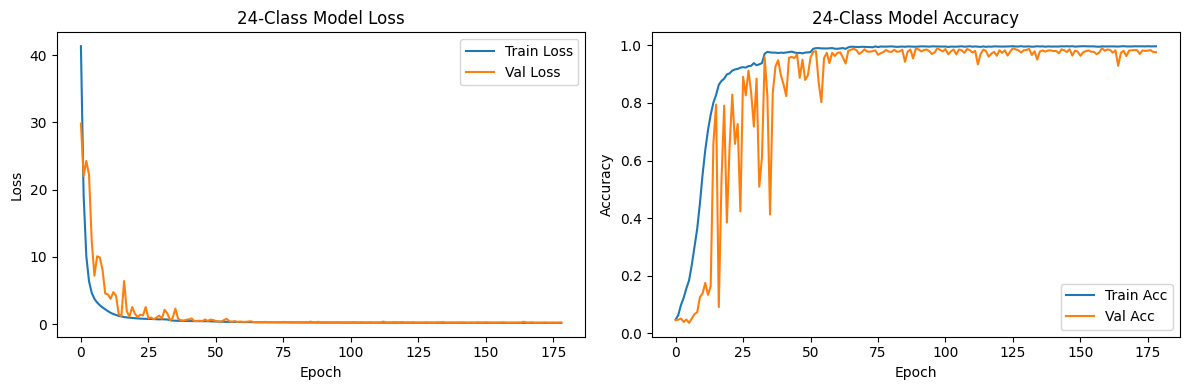

In [29]:
# evaluating model_class_24
y_pred_24 = model_class_24.predict(X_test)
y_pred_24_classes = np.argmax(y_pred_24, axis = 1)
y_pred_24_labels = revert_labels_to_24_classes(y_pred_24_classes)

error_24 = common_sense_error(y_test, y_pred_24_labels)
print(f"24-Class Model Common Sense Error: {error_24.round(2)} minutes")

# plotting training history
plt.figure(figsize = (12, 4))
plt.subplot(1, 2, 1)
plt.plot(history_class_24.history["loss"], label = "Train Loss")
plt.plot(history_class_24.history["val_loss"], label = "Val Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.title("24-Class Model Loss")

plt.subplot(1, 2, 2)
plt.plot(history_class_24.history["accuracy"], label = "Train Acc")
plt.plot(history_class_24.history["val_accuracy"], label = "Val Acc")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.title("24-Class Model Accuracy")
plt.tight_layout()
plt.show()

### Classification (72 classes - 10-minute intervals)

In [30]:
def labels_to_72_classes(labels):
    # converting the hour and minute labels to 72 classes
    total_minutes = labels[:, 0] * 60 + labels[:, 1]
    classes = (total_minutes // 10)
    return classes.astype(int)

def revert_labels_to_72_classes(classes):
    # reverting the 72 classes to hour and minute labels
    total_minutes = classes * 10 + 5
    total_minutes = total_minutes % 720
    hours = (total_minutes // 60) % 12
    minutes = total_minutes % 60
    return np.column_stack([hours, minutes])

# applying labels_to_72_classes to data (creating the 10min intervals)
y_train_72 = labels_to_72_classes(y_train)
y_valid_72 = labels_to_72_classes(y_valid)
y_test_72 = labels_to_72_classes(y_test)

# converting to categorical for classification
y_train_72_cat = to_categorical(y_train_72, 72)
y_valid_72_cat = to_categorical(y_valid_72, 72)
y_test_72_cat = to_categorical(y_test_72, 72)

In [31]:
# building and training model_class_72
model_class_72 = models.Sequential([
    # input layer
    layers.Input(shape = X_train.shape[1:]),

    # first convolutional block
    layers.Conv2D(32, (3, 3), activation = "relu", padding = "same",
                  kernel_regularizer = regularizers.l2(0.1)),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.1),

    # second convolutional block
    layers.Conv2D(64, (3, 3), activation = "relu", padding = "same",
                  kernel_regularizer = regularizers.l2(0.1)),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.1),

    # third convolutional block
    layers.Conv2D(128, (3, 3), activation = "relu", padding = "same",
                  kernel_regularizer = regularizers.l2(0.1)),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.1),

    # fourth convolutional block
    layers.Conv2D(256, (3, 3), activation = "relu", padding = "same",
                  kernel_regularizer = regularizers.l2(0.1)),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.1),

    layers.GlobalAveragePooling2D(),

    layers.Dense(256, activation = "relu",
                 kernel_regularizer = regularizers.l2(0.1)),
    layers.BatchNormalization(),
    layers.Dropout(0.2),

    # output layer
    layers.Dense(72, activation = "softmax")
])

model_class_72.compile(
    optimizer = Adam(learning_rate = 0.0001),
    loss = "categorical_crossentropy",
    metrics = ["accuracy"]
)

print("training model_class_72")
history_class_72 = model_class_72.fit(
    X_train, y_train_72_cat,
    validation_data = (X_valid, y_valid_72_cat),
    epochs = 200,
    batch_size = 32,
    callbacks = get_callbacks(),
    verbose = 0
)

training model_class_72
Epoch 122: early stopping
Restoring model weights from the end of the best epoch: 102.


57/57 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step
72-Class Model Common Sense Error: 3.72 minutes


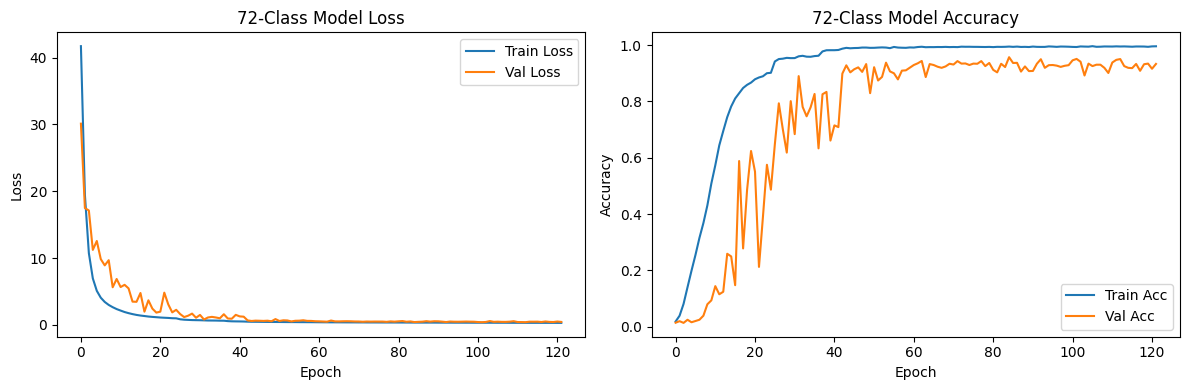

In [32]:
# evaluating model_class_72
y_pred_72 = model_class_72.predict(X_test)
y_pred_72_classes = np.argmax(y_pred_72, axis = 1)
y_pred_72_labels = revert_labels_to_72_classes(y_pred_72_classes)

error_72 = common_sense_error(y_test, y_pred_72_labels)
print(f"72-Class Model Common Sense Error: {error_72.round(2)} minutes")

# plotting training history
plt.figure(figsize = (12, 4))
plt.subplot(1, 2, 1)
plt.plot(history_class_72.history["loss"], label = "Train Loss")
plt.plot(history_class_72.history["val_loss"], label = "Val Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.title("72-Class Model Loss")

plt.subplot(1, 2, 2)
plt.plot(history_class_72.history["accuracy"], label = "Train Acc")
plt.plot(history_class_72.history["val_accuracy"], label = "Val Acc")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.title("72-Class Model Accuracy")
plt.tight_layout()
plt.show()

### Classification (720 classes - every minute)

In [33]:
def labels_to_720_classes(labels):
    # converting the hour and minute labels to 720 classes
    total_minutes = labels[:, 0] * 60 + labels[:, 1]
    return total_minutes.astype(int)

def revert_labels_to_720_classes(classes):
    # reverting the 720 classes to hour and minute labels
    classes = classes % 720
    hours = (classes // 60) % 12  # ensuring hours are in 0-11 range
    minutes = classes % 60
    return np.column_stack([hours, minutes])

# applying labels_to_720_classes to data (creating a class for each minute)
y_train_720 = labels_to_720_classes(y_train)
y_valid_720 = labels_to_720_classes(y_valid)
y_test_720 = labels_to_720_classes(y_test)

# converting to categorical for classification
y_train_720_cat = to_categorical(y_train_720, 720)
y_valid_720_cat = to_categorical(y_valid_720, 720)
y_test_720_cat = to_categorical(y_test_720, 720)

In [34]:
# building and training model_class_720
model_class_720 = models.Sequential([
    # input layer
    layers.Input(shape = X_train.shape[1:]),

    # first convolutional block
    layers.Conv2D(32, (3, 3), activation = "relu", padding = "same",
                  kernel_regularizer = regularizers.l2(0.1)),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.1),

    # second convolutional block
    layers.Conv2D(64, (3, 3), activation = "relu", padding = "same",
                  kernel_regularizer = regularizers.l2(0.1)),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.1),

    # third convolutional block
    layers.Conv2D(128, (3, 3), activation = "relu", padding = "same",
                  kernel_regularizer = regularizers.l2(0.1)),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.1),

    # fourth convolutional block
    layers.Conv2D(256, (3, 3), activation = "relu", padding = "same",
                  kernel_regularizer = regularizers.l2(0.1)),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.1),

    layers.GlobalAveragePooling2D(),

    layers.Dense(256, activation = "relu",
                 kernel_regularizer = regularizers.l2(0.1)),
    layers.BatchNormalization(),
    layers.Dropout(0.2),

    # output layer
    layers.Dense(720, activation = "softmax")
])

model_class_720.compile(
    optimizer = Adam(learning_rate = 0.0001),
    loss = "categorical_crossentropy",
    metrics = ["accuracy"]
)

print("training model_class_720")
history_class_720 = model_class_720.fit(
    X_train, y_train_720_cat,
    validation_data = (X_valid, y_valid_720_cat),
    epochs = 200,
    batch_size = 32,
    callbacks = get_callbacks(),
    verbose = 0
)

training model_class_720
Epoch 155: early stopping
Restoring model weights from the end of the best epoch: 135.


57/57 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step
720-Class Model Common Sense Error: 11.34 minutes


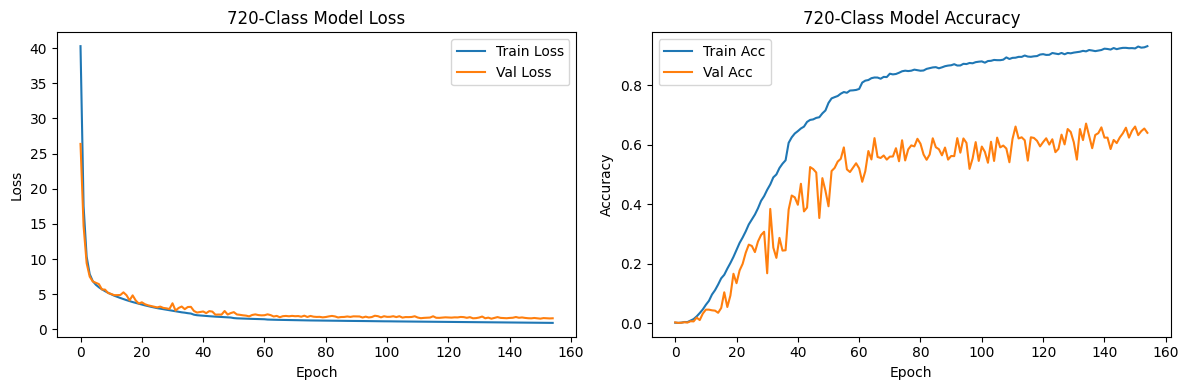

In [35]:
# evaluating model_class_720
y_pred_720 = model_class_720.predict(X_test)
y_pred_720_classes = np.argmax(y_pred_720, axis = 1)
y_pred_720_labels = revert_labels_to_720_classes(y_pred_720_classes)

error_720 = common_sense_error(y_test, y_pred_720_labels)
print(f"720-Class Model Common Sense Error: {error_720.round(2)} minutes")

# plotting training history
plt.figure(figsize = (12, 4))
plt.subplot(1, 2, 1)
plt.plot(history_class_720.history["loss"], label = "Train Loss")
plt.plot(history_class_720.history["val_loss"], label = "Val Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.title("720-Class Model Loss")

plt.subplot(1, 2, 2)
plt.plot(history_class_720.history["accuracy"], label = "Train Acc")
plt.plot(history_class_720.history["val_accuracy"], label = "Val Acc")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.title("720-Class Model Accuracy")
plt.tight_layout()
plt.show()

### Regression

In [36]:
def labels_to_regression(labels):
    # converting hour and minute labels to single continuous value
    continuous_values = labels[:, 0] + labels[:, 1] / 60.0
    return continuous_values.astype(float)

def revert_labels_to_regression(values):
    # reverting continuous values to hour and minute labels
    values = values % 12.0
    hours = np.floor(values).astype(int)
    minutes = np.round((values - np.floor(values)) * 60.0).astype(int)

    # handling the case where minutes round to 60
    hours = np.where(minutes == 60, (hours + 1) % 12, hours)
    minutes = np.where(minutes == 60, 0, minutes)

    return np.column_stack([hours, minutes])

# preparing regression targets
y_train_reg = labels_to_regression(y_train)
y_valid_reg = labels_to_regression(y_valid)
y_test_reg = labels_to_regression(y_test)

In [37]:
# building and training regression model
model_reg = models.Sequential([
    # input layer
    layers.Input(shape = X_train.shape[1:]),

    # first convolutional block
    layers.Conv2D(32, (3, 3), activation = "relu", padding = "same",
                  kernel_regularizer = regularizers.l2(0.1)),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.1),

    # second convolutional block
    layers.Conv2D(64, (3, 3), activation = "relu", padding = "same",
                  kernel_regularizer = regularizers.l2(0.1)),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.1),

    # third convolutional block
    layers.Conv2D(128, (3, 3), activation = "relu", padding = "same",
                  kernel_regularizer = regularizers.l2(0.1)),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.1),

    # fourth convolutional block
    layers.Conv2D(256, (3, 3), activation = "relu", padding = "same",
                  kernel_regularizer = regularizers.l2(0.1)),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.1),

    layers.GlobalAveragePooling2D(),

    layers.Dense(256, activation = "relu",
                 kernel_regularizer = regularizers.l2(0.1)),
    layers.BatchNormalization(),
    layers.Dropout(0.2),

    # output layer
    layers.Dense(1, activation = "linear")
])

model_reg.compile(
    optimizer = Adam(learning_rate = 0.0001),
    loss = "mse",
    metrics = ["mae"]
)

print("training model_reg")
history_reg = model_reg.fit(
    X_train, y_train_reg,
    validation_data = (X_valid, y_valid_reg),
    epochs = 200,
    batch_size = 32,
    callbacks = get_callbacks(),
    verbose = 0
)

training model_reg
Restoring model weights from the end of the best epoch: 197.


57/57 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step
Regression Model Common Sense Error: 20.28 minutes


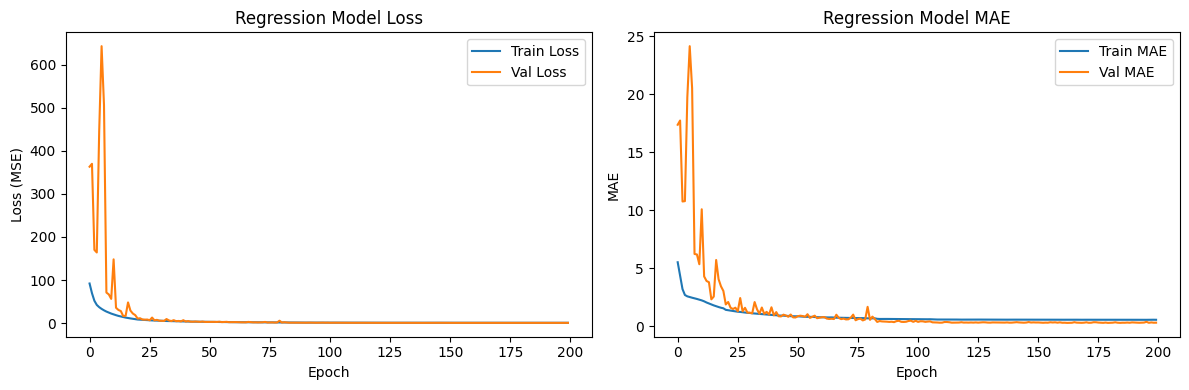

In [38]:
# evaluating model_reg
y_pred_reg = model_reg.predict(X_test)
y_pred_reg_labels = revert_labels_to_regression(y_pred_reg.flatten())

error_reg = common_sense_error(y_test, y_pred_reg_labels)
print(f"Regression Model Common Sense Error: {error_reg.round(2)} minutes")

# plotting training history
plt.figure(figsize = (12, 4))
plt.subplot(1, 2, 1)
plt.plot(history_reg.history["loss"], label = "Train Loss")
plt.plot(history_reg.history["val_loss"], label = "Val Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss (MSE)")
plt.legend()
plt.title("Regression Model Loss")

plt.subplot(1, 2, 2)
plt.plot(history_reg.history["mae"], label = "Train MAE")
plt.plot(history_reg.history["val_mae"], label = "Val MAE")
plt.xlabel("Epoch")
plt.ylabel("MAE")
plt.legend()
plt.title("Regression Model MAE")
plt.tight_layout()
plt.show()

### Multi-head Model (using classification for both hours and minutes and categorical crossentropy as loss function)

In [39]:
# preparing separate targets for hours and minutes
y_train_hours = y_train[:, 0]
y_train_minutes = y_train[:, 1]
y_valid_hours = y_valid[:, 0]
y_valid_minutes = y_valid[:, 1]
y_test_hours = y_test[:, 0]
y_test_minutes = y_test[:, 1]

# converting to categorical for classification
y_train_hours_cat = to_categorical(y_train_hours, 12)
y_valid_hours_cat = to_categorical(y_valid_hours, 12)
y_test_hours_cat = to_categorical(y_test_hours, 12)

y_train_minutes_cat = to_categorical(y_train_minutes, 60)
y_valid_minutes_cat = to_categorical(y_valid_minutes, 60)
y_test_minutes_cat = to_categorical(y_test_minutes, 60)

In [40]:
# building multi-head model using Functional API
inputs = layers.Input(shape = X_train.shape[1:])

x = layers.Conv2D(32, (3, 3), activation = "relu", padding = "same",
                  kernel_regularizer = regularizers.l2(0.1))(inputs)
x = layers.BatchNormalization()(x)
x = layers.MaxPooling2D((2, 2))(x)
x = layers.Dropout(0.1)(x)

x = layers.Conv2D(64, (3, 3), activation = "relu", padding = "same",
                  kernel_regularizer = regularizers.l2(0.1))(x)
x = layers.BatchNormalization()(x)
x = layers.MaxPooling2D((2, 2))(x)
x = layers.Dropout(0.1)(x)

x = layers.Conv2D(128, (3, 3), activation = "relu", padding = "same",
                  kernel_regularizer = regularizers.l2(0.1))(x)
x = layers.BatchNormalization()(x)
x = layers.MaxPooling2D((2, 2))(x)
x = layers.Dropout(0.1)(x)

x = layers.Conv2D(256, (3, 3), activation = "relu", padding = "same",
                  kernel_regularizer = regularizers.l2(0.1))(x)
x = layers.BatchNormalization()(x)
x = layers.MaxPooling2D((2, 2))(x)
x = layers.Dropout(0.1)(x)

x = layers.GlobalAveragePooling2D()(x)

x = layers.Dense(256, activation = "relu",
                 kernel_regularizer = regularizers.l2(0.1))(x)
x = layers.BatchNormalization()(x)
x = layers.Dropout(0.2)(x)

# hour head (classification)
hour_head = layers.Dense(64, activation = "relu", name = "hour_dense")(x)
hour_output = layers.Dense(12, activation = "softmax",
                           name = "hour_output")(hour_head)

# minute head (classification)
minute_head = layers.Dense(64, activation = "relu", name = "minute_dense")(x)
minute_output = layers.Dense(60, activation = "softmax",
                             name = "minute_output")(minute_head)

model_multihead = models.Model(inputs = inputs,
                               outputs = [hour_output, minute_output])

model_multihead.compile(
    optimizer = Adam(learning_rate = 0.0001),
    loss = {
        "hour_output": "categorical_crossentropy",
        "minute_output": "categorical_crossentropy"
    },
    loss_weights = {"hour_output": 1.0, "minute_output": 1.0},
    metrics = {"hour_output": "accuracy", "minute_output": "accuracy"}
)

In [41]:
# training multi-head model
print("training multi-head model")
history_multihead = model_multihead.fit(
    X_train,
    {"hour_output": y_train_hours_cat, "minute_output": y_train_minutes_cat},
    validation_data = (X_valid, {"hour_output": y_valid_hours_cat, "minute_output": y_valid_minutes_cat}),
    epochs = 200,
    batch_size = 32,
    callbacks = get_callbacks(),
    verbose = 0
)

training multi-head model
Epoch 127: early stopping
Restoring model weights from the end of the best epoch: 107.


57/57 ━━━━━━━━━━━━━━━━━━━━ 3s 22ms/step
Multi-head Model Common Sense Error: 1.01 minutes


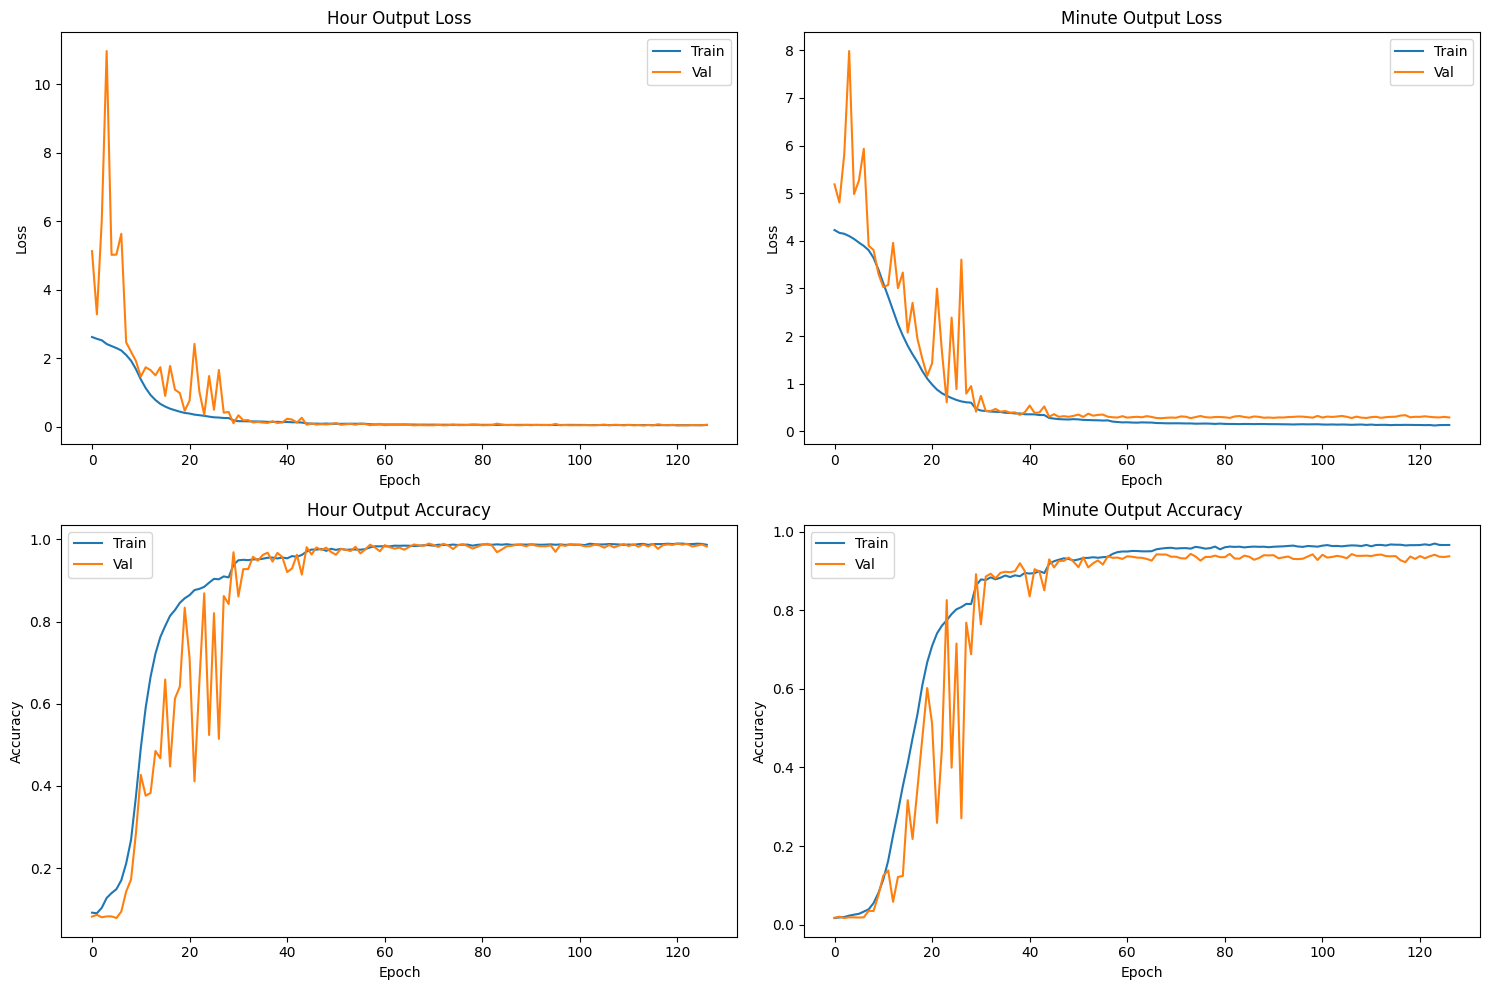

In [42]:
# evaluating multi-head model
hour_pred, minute_pred = model_multihead.predict(X_test)
y_pred_multihead = np.column_stack([
    np.argmax(hour_pred, axis = 1),
    np.argmax(minute_pred, axis = 1)
])

error_multihead = common_sense_error(y_test, y_pred_multihead)
print(f"Multi-head Model Common Sense Error: {error_multihead.round(2)} minutes")

# plotting training history
fig, axes = plt.subplots(2, 2, figsize = (15, 10))

# hour loss
axes[0, 0].plot(history_multihead.history["hour_output_loss"], label = "Train")
axes[0, 0].plot(history_multihead.history["val_hour_output_loss"], label = "Val")
axes[0, 0].set_xlabel("Epoch")
axes[0, 0].set_ylabel("Loss")
axes[0, 0].set_title("Hour Output Loss")
axes[0, 0].legend()

# minute loss
axes[0, 1].plot(history_multihead.history["minute_output_loss"], label = "Train")
axes[0, 1].plot(history_multihead.history["val_minute_output_loss"], label = "Val")
axes[0, 1].set_xlabel("Epoch")
axes[0, 1].set_ylabel("Loss")
axes[0, 1].set_title("Minute Output Loss")
axes[0, 1].legend()

# hour accuracy
axes[1, 0].plot(history_multihead.history["hour_output_accuracy"], label = "Train")
axes[1, 0].plot(history_multihead.history["val_hour_output_accuracy"], label = "Val")
axes[1, 0].set_xlabel("Epoch")
axes[1, 0].set_ylabel("Accuracy")
axes[1, 0].set_title("Hour Output Accuracy")
axes[1, 0].legend()

# minute accuracy
axes[1, 1].plot(history_multihead.history["minute_output_accuracy"], label = "Train")
axes[1, 1].plot(history_multihead.history["val_minute_output_accuracy"], label = "Val")
axes[1, 1].set_xlabel("Epoch")
axes[1, 1].set_ylabel("Accuracy")
axes[1, 1].set_title("Minute Output Accuracy")
axes[1, 1].legend()

plt.tight_layout()
plt.show()

### Multi-head Model (using classification for hours and regression for minutes with categorical crossentropy and MSE as loss functions respectively)

In [43]:
# preparing separate targets for hours (classification) and minutes (regression)
# hours as 12 classes (0-11)
# minutes as continuous values for regression
y_train_hours_reg = y_train[:, 0]
y_train_minutes_reg = y_train[:, 1].astype("float32")
y_valid_hours_reg = y_valid[:, 0]
y_valid_minutes_reg = y_valid[:, 1].astype("float32")
y_test_hours_reg = y_test[:, 0]
y_test_minutes_reg = y_test[:, 1].astype("float32")

# converting hours to categorical for classification
y_train_hours_reg_cat = to_categorical(y_train_hours_reg, 12)
y_valid_hours_reg_cat = to_categorical(y_valid_hours_reg, 12)
y_test_hours_reg_cat = to_categorical(y_test_hours_reg, 12)

# normalizing minutes for better regression
y_train_minutes_norm = y_train_minutes_reg / 59.0
y_valid_minutes_norm = y_valid_minutes_reg / 59.0
y_test_minutes_norm = y_test_minutes_reg / 59.0

In [44]:
# building multi-head model using Functional API
inputs = layers.Input(shape = X_train.shape[1:])

x = layers.Conv2D(32, (3, 3), activation = "relu", padding = "same",
                  kernel_regularizer = regularizers.l2(0.1))(inputs)
x = layers.BatchNormalization()(x)
x = layers.MaxPooling2D((2, 2))(x)
x = layers.Dropout(0.1)(x)

x = layers.Conv2D(64, (3, 3), activation = "relu", padding = "same",
                  kernel_regularizer = regularizers.l2(0.1))(x)
x = layers.BatchNormalization()(x)
x = layers.MaxPooling2D((2, 2))(x)
x = layers.Dropout(0.1)(x)

x = layers.Conv2D(128, (3, 3), activation = "relu", padding = "same",
                  kernel_regularizer = regularizers.l2(0.1))(x)
x = layers.BatchNormalization()(x)
x = layers.MaxPooling2D((2, 2))(x)
x = layers.Dropout(0.1)(x)

x = layers.Conv2D(256, (3, 3), activation = "relu", padding = "same",
                  kernel_regularizer = regularizers.l2(0.1))(x)
x = layers.BatchNormalization()(x)
x = layers.MaxPooling2D((2, 2))(x)
x = layers.Dropout(0.1)(x)

x = layers.GlobalAveragePooling2D()(x)

x = layers.Dense(256, activation = "relu",
                 kernel_regularizer = regularizers.l2(0.1))(x)
x = layers.BatchNormalization()(x)
x = layers.Dropout(0.2)(x)

# hour head (classification)
hour_head = layers.Dense(64, activation = "relu", name = "hour_dense")(x)
hour_output = layers.Dense(12, activation = "softmax",
                           name = "hour_output")(hour_head)

# minute head (regression)
minute_head = layers.Dense(64, activation = "relu", name = "minute_dense")(x)
minute_output = layers.Dense(1, activation = "sigmoid",
                             name = "minute_output")(minute_head)

model_multihead_reg = models.Model(inputs = inputs,
                                   outputs = [hour_output, minute_output])

model_multihead_reg.compile(
    optimizer = Adam(learning_rate = 0.0001),
    loss = {
        "hour_output": "categorical_crossentropy",
        "minute_output": "mse"
    },
    loss_weights = {"hour_output": 1.0, "minute_output": 1.0},
    metrics = {
        "hour_output": "accuracy",
        "minute_output": "mae"
    }
)

In [45]:
# training multi-head model with regression
print("training multi-head model (classification + regression)")
history_multihead_reg = model_multihead_reg.fit(
    X_train,
    {"hour_output": y_train_hours_reg_cat,
     "minute_output": y_train_minutes_norm},
    validation_data = (X_valid, {"hour_output": y_valid_hours_reg_cat,
                                 "minute_output": y_valid_minutes_norm}),
    epochs = 200,
    batch_size = 32,
    callbacks = get_callbacks(),
    verbose = 0
)

training multi-head model (classification + regression)
Epoch 166: early stopping
Restoring model weights from the end of the best epoch: 146.


57/57 ━━━━━━━━━━━━━━━━━━━━ 4s 44ms/step
Multi-head Model (Classification + Regression) Common Sense Error: 3.9 minutes
hour classification accuracy: 98.22%
minute mean absolute error: 3.03 minutes


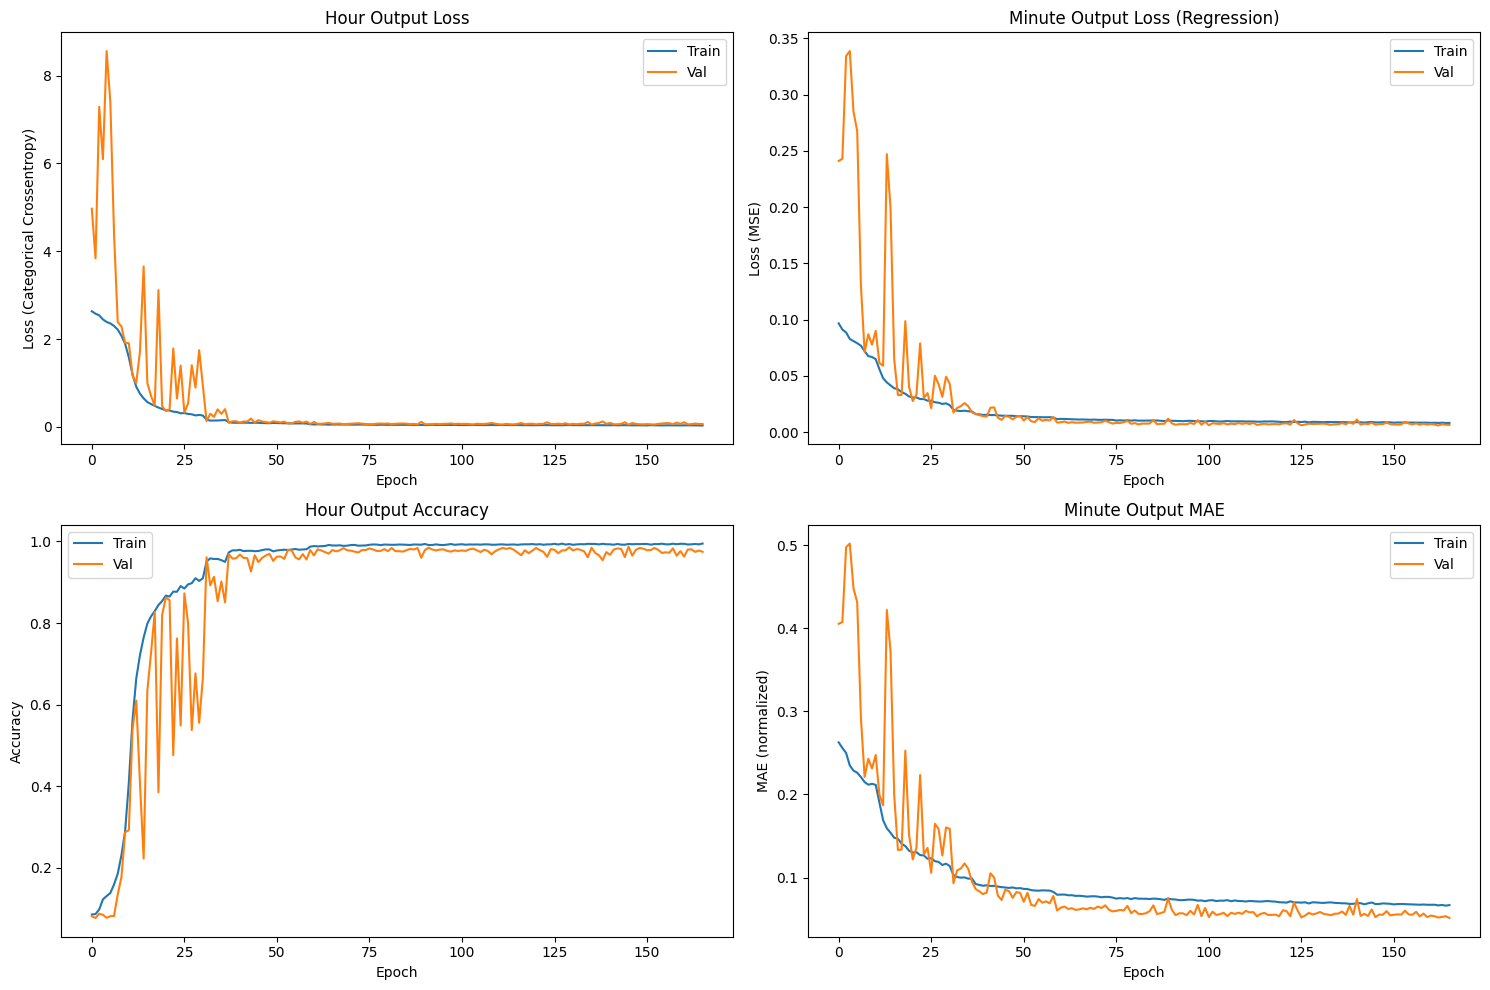

In [46]:
# evaluating multi-head regression model
hour_pred_reg, minute_pred_reg = model_multihead_reg.predict(X_test)

# converting predictions back to original format
y_pred_hours_reg = np.argmax(hour_pred_reg, axis = 1)
y_pred_minutes_reg = np.round(minute_pred_reg.flatten() * 59.0).astype(int)
y_pred_minutes_reg = np.clip(y_pred_minutes_reg, 0, 59)

y_pred_multihead_reg = np.column_stack([y_pred_hours_reg, y_pred_minutes_reg])

error_multihead_reg = common_sense_error(y_test, y_pred_multihead_reg)
print(f"Multi-head Model (Classification + Regression) Common Sense Error: {error_multihead_reg.round(2)} minutes")

# calculating individual accuracies
hour_accuracy_reg = np.mean(y_pred_hours_reg == y_test_hours_reg)
minute_mae_reg = np.mean(np.abs(y_pred_minutes_reg - y_test_minutes_reg))
print(f"hour classification accuracy: {(hour_accuracy_reg * 100).round(2)}%")
print(f"minute mean absolute error: {minute_mae_reg.round(2)} minutes")

# plotting training history
fig, axes = plt.subplots(2, 2, figsize = (15, 10))

# hour loss
axes[0, 0].plot(history_multihead_reg.history["hour_output_loss"],
                label = "Train")
axes[0, 0].plot(history_multihead_reg.history["val_hour_output_loss"],
                label = "Val")
axes[0, 0].set_xlabel("Epoch")
axes[0, 0].set_ylabel("Loss (Categorical Crossentropy)")
axes[0, 0].set_title("Hour Output Loss")
axes[0, 0].legend()

# minute loss
axes[0, 1].plot(history_multihead_reg.history["minute_output_loss"],
                label = "Train")
axes[0, 1].plot(history_multihead_reg.history["val_minute_output_loss"],
                label = "Val")
axes[0, 1].set_xlabel("Epoch")
axes[0, 1].set_ylabel("Loss (MSE)")
axes[0, 1].set_title("Minute Output Loss (Regression)")
axes[0, 1].legend()

# hour accuracy
axes[1, 0].plot(history_multihead_reg.history["hour_output_accuracy"],
                label = "Train")
axes[1, 0].plot(history_multihead_reg.history["val_hour_output_accuracy"],
                label = "Val")
axes[1, 0].set_xlabel("Epoch")
axes[1, 0].set_ylabel("Accuracy")
axes[1, 0].set_title("Hour Output Accuracy")
axes[1, 0].legend()

# minute MAE
axes[1, 1].plot(history_multihead_reg.history["minute_output_mae"],
                label = "Train")
axes[1, 1].plot(history_multihead_reg.history["val_minute_output_mae"],
                label = "Val")
axes[1, 1].set_xlabel("Epoch")
axes[1, 1].set_ylabel("MAE (normalized)")
axes[1, 1].set_title("Minute Output MAE")
axes[1, 1].legend()

plt.tight_layout()
plt.show()

### Multi-head Model with Different Loss Weights

In [47]:
# function to build and train multi-head model with custom loss weights
def build_and_train_multihead_weighted(hour_weight, minute_weight, model_name):
    # building multi-head model using Functional API
    inputs = layers.Input(shape = X_train.shape[1:])

    x = layers.Conv2D(32, (3, 3), activation = "relu", padding = "same",
                      kernel_regularizer = regularizers.l2(0.1))(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D((2, 2))(x)
    x = layers.Dropout(0.1)(x)

    x = layers.Conv2D(64, (3, 3), activation = "relu", padding = "same",
                      kernel_regularizer = regularizers.l2(0.1))(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D((2, 2))(x)
    x = layers.Dropout(0.1)(x)

    x = layers.Conv2D(128, (3, 3), activation = "relu", padding = "same",
                      kernel_regularizer = regularizers.l2(0.1))(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D((2, 2))(x)
    x = layers.Dropout(0.1)(x)

    # fourth convolutional block
    x = layers.Conv2D(256, (3, 3), activation = "relu", padding = "same",
                      kernel_regularizer = regularizers.l2(0.1))(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D((2, 2))(x)
    x = layers.Dropout(0.1)(x)

    x = layers.GlobalAveragePooling2D()(x)

    x = layers.Dense(256, activation = "relu",
                     kernel_regularizer = regularizers.l2(0.1))(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.2)(x)

    # hour head (classification)
    hour_head = layers.Dense(64, activation = "relu", name = "hour_dense")(x)
    hour_output = layers.Dense(12, activation = "softmax",
                               name = "hour_output")(hour_head)

    # minute head (classification)
    minute_head = layers.Dense(64, activation = "relu", name = "minute_dense")(x)
    minute_output = layers.Dense(60, activation = "softmax",
                                 name = "minute_output")(minute_head)

    model = models.Model(inputs = inputs,
                         outputs = [hour_output, minute_output])

    model.compile(
        optimizer = Adam(learning_rate = 0.0001),
        loss = {
            "hour_output": "categorical_crossentropy",
            "minute_output": "categorical_crossentropy"
        },
        loss_weights = {"hour_output": hour_weight, "minute_output": minute_weight},
        metrics = {"hour_output": "accuracy", "minute_output": "accuracy"}
    )

    print(f"training {model_name} (weights - hour:{hour_weight}, minute:{minute_weight})")
    history = model.fit(
        X_train,
        {"hour_output": y_train_hours_cat, "minute_output": y_train_minutes_cat},
        validation_data = (X_valid, {"hour_output": y_valid_hours_cat,
                                     "minute_output": y_valid_minutes_cat}),
        epochs = 200,
        batch_size = 32,
        callbacks = get_callbacks(),
        verbose = 0
    )

    # evaluating the model
    hour_pred, minute_pred = model.predict(X_test)
    y_pred = np.column_stack([
        np.argmax(hour_pred, axis = 1),
        np.argmax(minute_pred, axis = 1)
    ])

    error = common_sense_error(y_test, y_pred)

    return model, history, error

In [48]:
# testing different weight ratios
weight_configs = [
    (3, 1, "Multi-head 3:1"),
    (2.5, 1, "Multi-head 2.5:1"),
    (2, 1, "Multi-head 2:1"),
    (1.5, 1, "Multi-head 1.5:1"),
    (1, 1, "Multi-head 1:1")
]

# storing results
weighted_models = {}
weighted_histories = {}
weighted_errors = {}

for hour_w, minute_w, name in weight_configs:
    model, history, error = build_and_train_multihead_weighted(hour_w, minute_w, name)
    weighted_models[name] = model
    weighted_histories[name] = history
    weighted_errors[name] = error
    print(f"{name} Common Sense Error: {error.round(2)} minutes")

training Multi-head 3:1 (weights - hour:3, minute:1)
Epoch 164: early stopping
Restoring model weights from the end of the best epoch: 144.
57/57 ━━━━━━━━━━━━━━━━━━━━ 3s 24ms/step
Multi-head 3:1 Common Sense Error: 2.1 minutes
training Multi-head 2.5:1 (weights - hour:2.5, minute:1)
Epoch 144: early stopping
Restoring model weights from the end of the best epoch: 124.
57/57 ━━━━━━━━━━━━━━━━━━━━ 3s 22ms/step
Multi-head 2.5:1 Common Sense Error: 0.86 minutes
training Multi-head 2:1 (weights - hour:2, minute:1)
Restoring model weights from the end of the best epoch: 187.
57/57 ━━━━━━━━━━━━━━━━━━━━ 3s 23ms/step
Multi-head 2:1 Common Sense Error: 1.02 minutes
training Multi-head 1.5:1 (weights - hour:1.5, minute:1)
Epoch 169: early stopping
Restoring model weights from the end of the best epoch: 149.
57/57 ━━━━━━━━━━━━━━━━━━━━ 3s 23ms/step
Multi-head 1.5:1 Common Sense Error: 1.06 minutes
training Multi-head 1:1 (weights - hour:1, minute:1)
Epoch 150: early stopping
Restoring model weights 

best configuration: Multi-head 2.5:1
best common sense error: 0.86 minutes


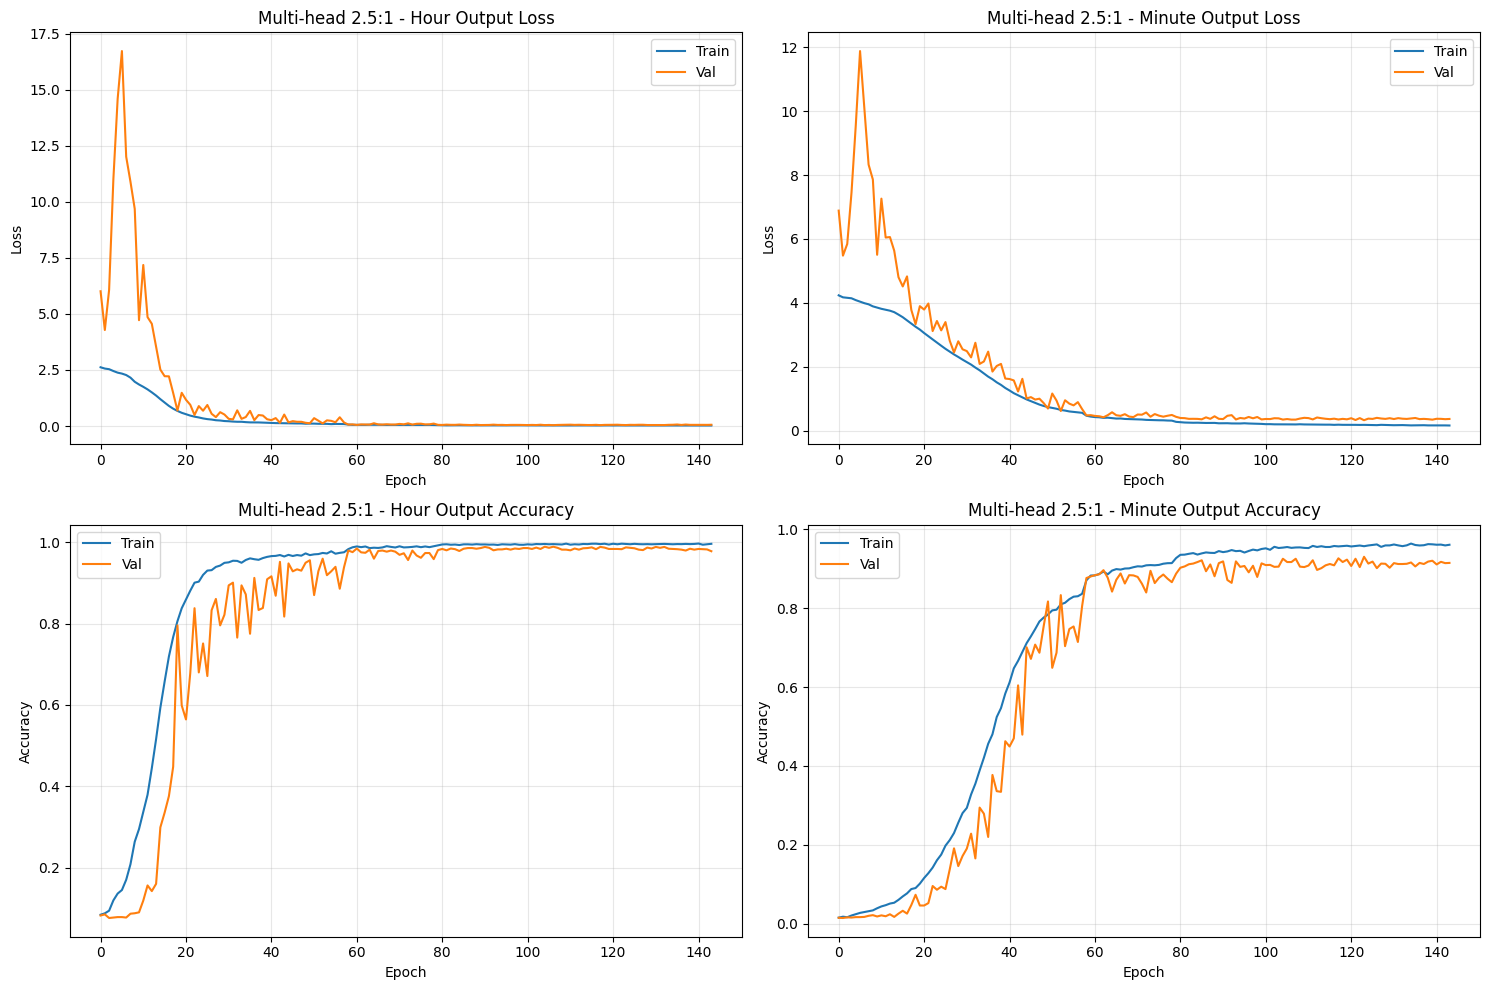

In [49]:
# detailed analysis of the best performing weight configuration
best_config = min(weighted_errors, key = weighted_errors.get)
best_error = weighted_errors[best_config]
best_history = weighted_histories[best_config]

print(f"best configuration: {best_config}")
print(f"best common sense error: {best_error.round(2)} minutes")

# plotting training history for best configuration
fig, axes = plt.subplots(2, 2, figsize = (15, 10))

# hour loss
axes[0, 0].plot(best_history.history["hour_output_loss"], label = "Train")
axes[0, 0].plot(best_history.history["val_hour_output_loss"], label = "Val")
axes[0, 0].set_xlabel("Epoch")
axes[0, 0].set_ylabel("Loss")
axes[0, 0].set_title(f"{best_config} - Hour Output Loss")
axes[0, 0].legend()
axes[0, 0].grid(alpha = 0.3)

# minute loss
axes[0, 1].plot(best_history.history["minute_output_loss"], label = "Train")
axes[0, 1].plot(best_history.history["val_minute_output_loss"], label = "Val")
axes[0, 1].set_xlabel("Epoch")
axes[0, 1].set_ylabel("Loss")
axes[0, 1].set_title(f"{best_config} - Minute Output Loss")
axes[0, 1].legend()
axes[0, 1].grid(alpha = 0.3)

# hour accuracy
axes[1, 0].plot(best_history.history["hour_output_accuracy"], label = "Train")
axes[1, 0].plot(best_history.history["val_hour_output_accuracy"], label = "Val")
axes[1, 0].set_xlabel("Epoch")
axes[1, 0].set_ylabel("Accuracy")
axes[1, 0].set_title(f"{best_config} - Hour Output Accuracy")
axes[1, 0].legend()
axes[1, 0].grid(alpha = 0.3)

# minute accuracy
axes[1, 1].plot(best_history.history["minute_output_accuracy"], label = "Train")
axes[1, 1].plot(best_history.history["val_minute_output_accuracy"], label = "Val")
axes[1, 1].set_xlabel("Epoch")
axes[1, 1].set_ylabel("Accuracy")
axes[1, 1].set_title(f"{best_config} - Minute Output Accuracy")
axes[1, 1].legend()
axes[1, 1].grid(alpha = 0.3)

plt.tight_layout()
plt.show()

In [50]:
# comparing weighted models
print("comparison of different loss weight ratios:")
for name in weighted_errors.keys():
    print(f"{name}: {weighted_errors[name].round(2)} minutes")

comparison of different loss weight ratios:
Multi-head 3:1: 2.1 minutes
Multi-head 2.5:1: 0.86 minutes
Multi-head 2:1: 1.02 minutes
Multi-head 1.5:1: 1.06 minutes
Multi-head 1:1: 1.07 minutes


In [51]:
# comparing all models
print("common sense error of all models")
print("classification models:")
print(f"1. classification (24 classes):       {error_24.round(2)} minutes")
print(f"2. classification (72 classes):       {error_72.round(2)} minutes")
print(f"3. classification (720 classes):      {error_720.round(2)} minutes")

print("regression model:")
print(f"4. regression (single output):        {error_reg.round(2)} minutes")

print("multi-head models:")
print(f"5. multi-head (class + class, 1:1):   {error_multihead.round(2)} minutes")
print(f"6. multi-head (class + reg, 1:1):     {error_multihead_reg.round(2)} minutes")

print("multi-head models with different loss weights:")
for i, (name, error) in enumerate(weighted_errors.items(), start = 7):
    print(f"{i}. {name}: {error.round(2)} minutes")

# finding best overall model
all_errors = {
    "Classification (24 classes)": error_24,
    "Classification (72 classes)": error_72,
    "Classification (720 classes)": error_720,
    "Regression": error_reg,
    "Multi-head (class+class, 1:1)": error_multihead,
    "Multi-head (class+reg, 1:1)": error_multihead_reg,
    **weighted_errors
}

best_model = min(all_errors, key = all_errors.get)
best_error = all_errors[best_model]
print(f"best model: {best_model}")
print(f"common sense error: {best_error.round(2)} minutes")

common sense error of all models
classification models:
1. classification (24 classes):       8.1 minutes
2. classification (72 classes):       3.72 minutes
3. classification (720 classes):      11.34 minutes
regression model:
4. regression (single output):        20.28 minutes
multi-head models:
5. multi-head (class + class, 1:1):   1.01 minutes
6. multi-head (class + reg, 1:1):     3.9 minutes
multi-head models with different loss weights:
7. Multi-head 3:1: 2.1 minutes
8. Multi-head 2.5:1: 0.86 minutes
9. Multi-head 2:1: 1.02 minutes
10. Multi-head 1.5:1: 1.06 minutes
11. Multi-head 1:1: 1.07 minutes
best model: Multi-head 2.5:1
common sense error: 0.86 minutes
